# TGT-M: implementation with results and charts (Review 2)
**Team 7, 21CSC314P Big Data Essentials.** *TGT-M: A Temporal Gated Transformer Model for Seasonal Groundwater Stress Assessment and Cross-Region Generalization Across India Using Multimodal Data*

Every section below matches a slide of the Review 2 presentation. Cells run top to bottom; the saved outputs and charts are already in this file, so you can **present without running anything**, or press *Run all* (about 6 to 8 minutes on a CPU) to regenerate them.

| Section | What it shows | Slide |
|---|---|---|
| 1 | Dataset: 2,759 wells, rainfall, wells per state | Dataset |
| 2 | Architecture diagrams, **TGT-M built from the real code**, shape of every stage | Proposed model, Architecture |
| 3 | **Apache Spark** recomputes the past-only baseline and anomaly and matches the pipeline | Preprocessing (Spark) |
| 4 | Preprocessing results: coverage, stress classes, **error metrics before vs after cleaning** | Results of preprocessing |
| 5 | TGT-M inputs, the label computed by hand, source code, **live mini training** | Classification (TGT-M) |
| 6 | TGT-M results: metrics, confusion matrix, predictions, interpretability | Results: proposed model |
| 7 | Comparison with six existing models, rainfall effect, unseen states | Comparison |
| 8 | The two pre-registered tests | Pre-registered tests |
| 9 | Findings and an automatic self-check | Key findings |

**Honest summary:** TGT-M ranks 5th of 7 learned models on point accuracy; its supported strengths are better 80% prediction intervals and a smaller loss than LSTM / 1D-CNN when recent readings are missing.

## 0 · Setup
Finds the project files (zip upload, Kaggle dataset or GitHub), checks libraries, sets chart style.

In [1]:
import os, sys, glob, zipfile, subprocess, time, shutil
from pathlib import Path
BUNDLE_ZIP = None      # e.g. "/content/bde_bundle_core.zip" if auto-detect fails
GITHUB_URL = "https://github.com/dhruvvvgg/bde-team7.git"   # only works after the project was pushed

ON_KAGGLE = Path("/kaggle").exists()
ON_COLAB = (not ON_KAGGLE) and Path("/content").exists()
WORK = Path("/kaggle/working") if ON_KAGGLE else Path("/content") if ON_COLAB else Path.cwd()

def looks_ok(p):
    p = Path(p); return (p / "modeling" / "data.py").exists() and (p / "processed" / "gw_features_by_state").exists()

def writable(c):
    """Kaggle mounts datasets read-only; copy the project to the writable working folder so quick/full mode can write results."""
    c = Path(c)
    if str(c).startswith("/kaggle/input"):
        dest = WORK / "bde-team7"
        if not looks_ok(dest):
            print("copying the project from the read-only dataset to", dest, "...")
            shutil.copytree(c, dest, dirs_exist_ok=True)
        return dest
    return c

def find_root():
    cands = [os.environ.get("BDE_ROOT"), Path.cwd(), Path.cwd().parent, WORK / "bde-team7"]
    cands += [Path(p).parent.parent for p in glob.glob("/kaggle/input/**/modeling/data.py", recursive=True)]
    for c in cands:
        if c and looks_ok(c): return writable(c)
    zips = ([BUNDLE_ZIP] if BUNDLE_ZIP else []) + glob.glob("/kaggle/input/**/bde_bundle_core*.zip", recursive=True) + glob.glob("/content/**/bde_bundle_core*.zip", recursive=True) + glob.glob(str(Path.cwd() / "bde_bundle_core*.zip"))
    for z in zips:
        if z and Path(z).exists():
            print("unzipping", Path(z).name); zipfile.ZipFile(z).extractall(WORK)
            for c in (WORK / "bde-team7", WORK):
                if looks_ok(c): return c
    dest = WORK / "bde-team7"
    if not dest.exists():
        r = subprocess.run(["git", "clone", "-q", "--depth", "1", "-b", "review2-modeling", GITHUB_URL, str(dest)])   # branch until merged into main
        if r.returncode: subprocess.run(["git", "clone", "-q", "--depth", "1", GITHUB_URL, str(dest)])
    if looks_ok(dest): return dest
    raise SystemExit("Project files not found: upload bde_bundle_core.zip (Colab: Files panel; Kaggle: Add Data) and rerun.")

ROOT = find_root(); os.environ["BDE_ROOT"] = str(ROOT); os.chdir(ROOT)
print("platform:", "Kaggle" if ON_KAGGLE else "Colab" if ON_COLAB else "local machine", "| project folder:", ROOT.name, "| cpus:", os.cpu_count())

platform: local machine | project folder: bde-team7 | cpus: 12


In [2]:
import importlib
miss = [p for m, p in {"xgboost": "xgboost", "pyarrow": "pyarrow", "sklearn": "scikit-learn", "scipy": "scipy"}.items() if importlib.util.find_spec(m) is None]
if miss: subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + miss)
import torch                                   # import torch BEFORE pandas (matters on Windows; harmless elsewhere)
import numpy as np, pandas as pd
sys.path.insert(0, str(ROOT / "modeling")); sys.path.insert(0, str(ROOT / "src"))
print("torch", torch.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

torch 2.14.0+cpu | pandas 3.0.2 | numpy 2.5.3


In [3]:
import io, json, inspect, importlib.util, contextlib, shutil
from IPython.display import display, Image
import plotly.graph_objects as go, plotly.io as pio
pio.templates.default = "plotly_white"
if not (ON_KAGGLE or ON_COLAB):                       # local run: save a PNG copy of each chart in the notebook as well
    try:
        import kaleido; pio.renderers.default = "plotly_mimetype+png"
    except Exception:
        pass
PAL = {"A": "#1F4E79", "B": "#C55A11", "T": "#7030A0", "G": "#548235", "grey": "#7F7F7F"}
LAB = {"CNN1D": "1D-CNN", "TGT-M": "TGT-M (proposed)", "Prev. round": "Previous round", "Same season LY": "Same season last year"}
lab = lambda m: LAB.get(m, m)
T = ROOT / "results" / "tables"
CHECKS = []
def check(name, ok):
    CHECKS.append((name, bool(ok))); print(("PASS  " if ok else "FAIL  ") + name)
import re
SAVE = bool(os.environ.get("BDE_SAVE_CHARTS"))          # set on the team laptop to save every chart as a PNG for the slides
CH = ROOT / "notebooks" / "assets" / "charts"
FIGS = ROOT / "reports" / "figures"
def slug(t): return re.sub(r"[^a-z0-9]+", "_", t.lower()).strip("_")[:90]
def pic(path, width=900):
    """Show a figure produced by the preprocessing pipeline (reports/figures) exactly as it is in the slides."""
    display(Image(filename=str(path), width=width))
def show(fig, title, x, y, h=440, **kw):
    fig.update_layout(title=dict(text=title, x=0.01), xaxis_title=x, yaxis_title=y, height=h, font=dict(family="Times New Roman", size=14),
                      **{**dict(margin=dict(l=70, r=20, t=70, b=70), legend=dict(orientation="h", y=-0.3)), **kw})
    fig.show()
    if SAVE:
        CH.mkdir(parents=True, exist_ok=True)
        big = go.Figure(fig); big.update_layout(font=dict(family="Times New Roman", size=21), title=dict(font=dict(size=24)), legend=dict(font=dict(size=19)))
        big.write_image(str(CH / (slug(title) + ".png")), width=1000, height=max(h, 640), scale=2)    # larger text copy for the slides
def lollipop(fig, labels, values, color, horizontal=False, fmt="{:,.2f}", base=0.0):
    """Lollipop (stem + dot): used instead of bars."""
    xs, ys = [], []
    for l, v in zip(labels, values):
        xs += [l, l, None]; ys += [base, v, None]
    stem = dict(mode="lines", line=dict(color="#9E9E9E", width=3), showlegend=False, hoverinfo="skip")
    dots = dict(mode="markers+text", marker=dict(size=12, color=color), text=[fmt.format(v) for v in values], showlegend=False)
    if horizontal:
        fig.add_scatter(x=ys, y=xs, **stem); fig.add_scatter(x=list(values), y=list(labels), textposition="middle right", **dots)
    else:
        fig.add_scatter(x=xs, y=ys, **stem); fig.add_scatter(x=list(labels), y=list(values), textposition="top center", **dots)
def dumbbell(fig, labels, a, b, name_a, name_b, ca, cb):
    """Dumbbell: two dots per category joined by a line (e.g. without vs with rainfall)."""
    xs, ys = [], []
    for l, u, v in zip(labels, a, b):
        xs += [l, l, None]; ys += [u, v, None]
    fig.add_scatter(x=xs, y=ys, mode="lines", line=dict(color="#9E9E9E", width=3), showlegend=False, hoverinfo="skip")
    fig.add_scatter(x=list(labels), y=list(a), mode="markers", marker=dict(size=12, color=ca), name=name_a)
    fig.add_scatter(x=list(labels), y=list(b), mode="markers", marker=dict(size=12, color=cb), name=name_b)
print("charts ready")

charts ready


## 1 · Dataset (slide: Dataset)
Groundwater depth from the CGWB network (Figshare, Kuruva et al. 2025), **2,759 wells in 19 states**, four rounds a year (January, May, August, November), 2000 to 2022; **CHIRPS v3** monthly rainfall at each well; static well metadata. This is the *multimodal* input: time series + gridded rainfall + well attributes.

,Item,Value
0,"Well-round rows (2,759 wells x 92 rounds)","253,828"
1,Wells,"2,759"
2,States / districts,19 / 365
3,Rounds per year x years,4 x 23 (2000-2022)
4,Rows with a reading,"219,258"
5,Missing readings,13.62%
6,"Rows with a rainfall value (CHIRPS, month befo...","253,828"


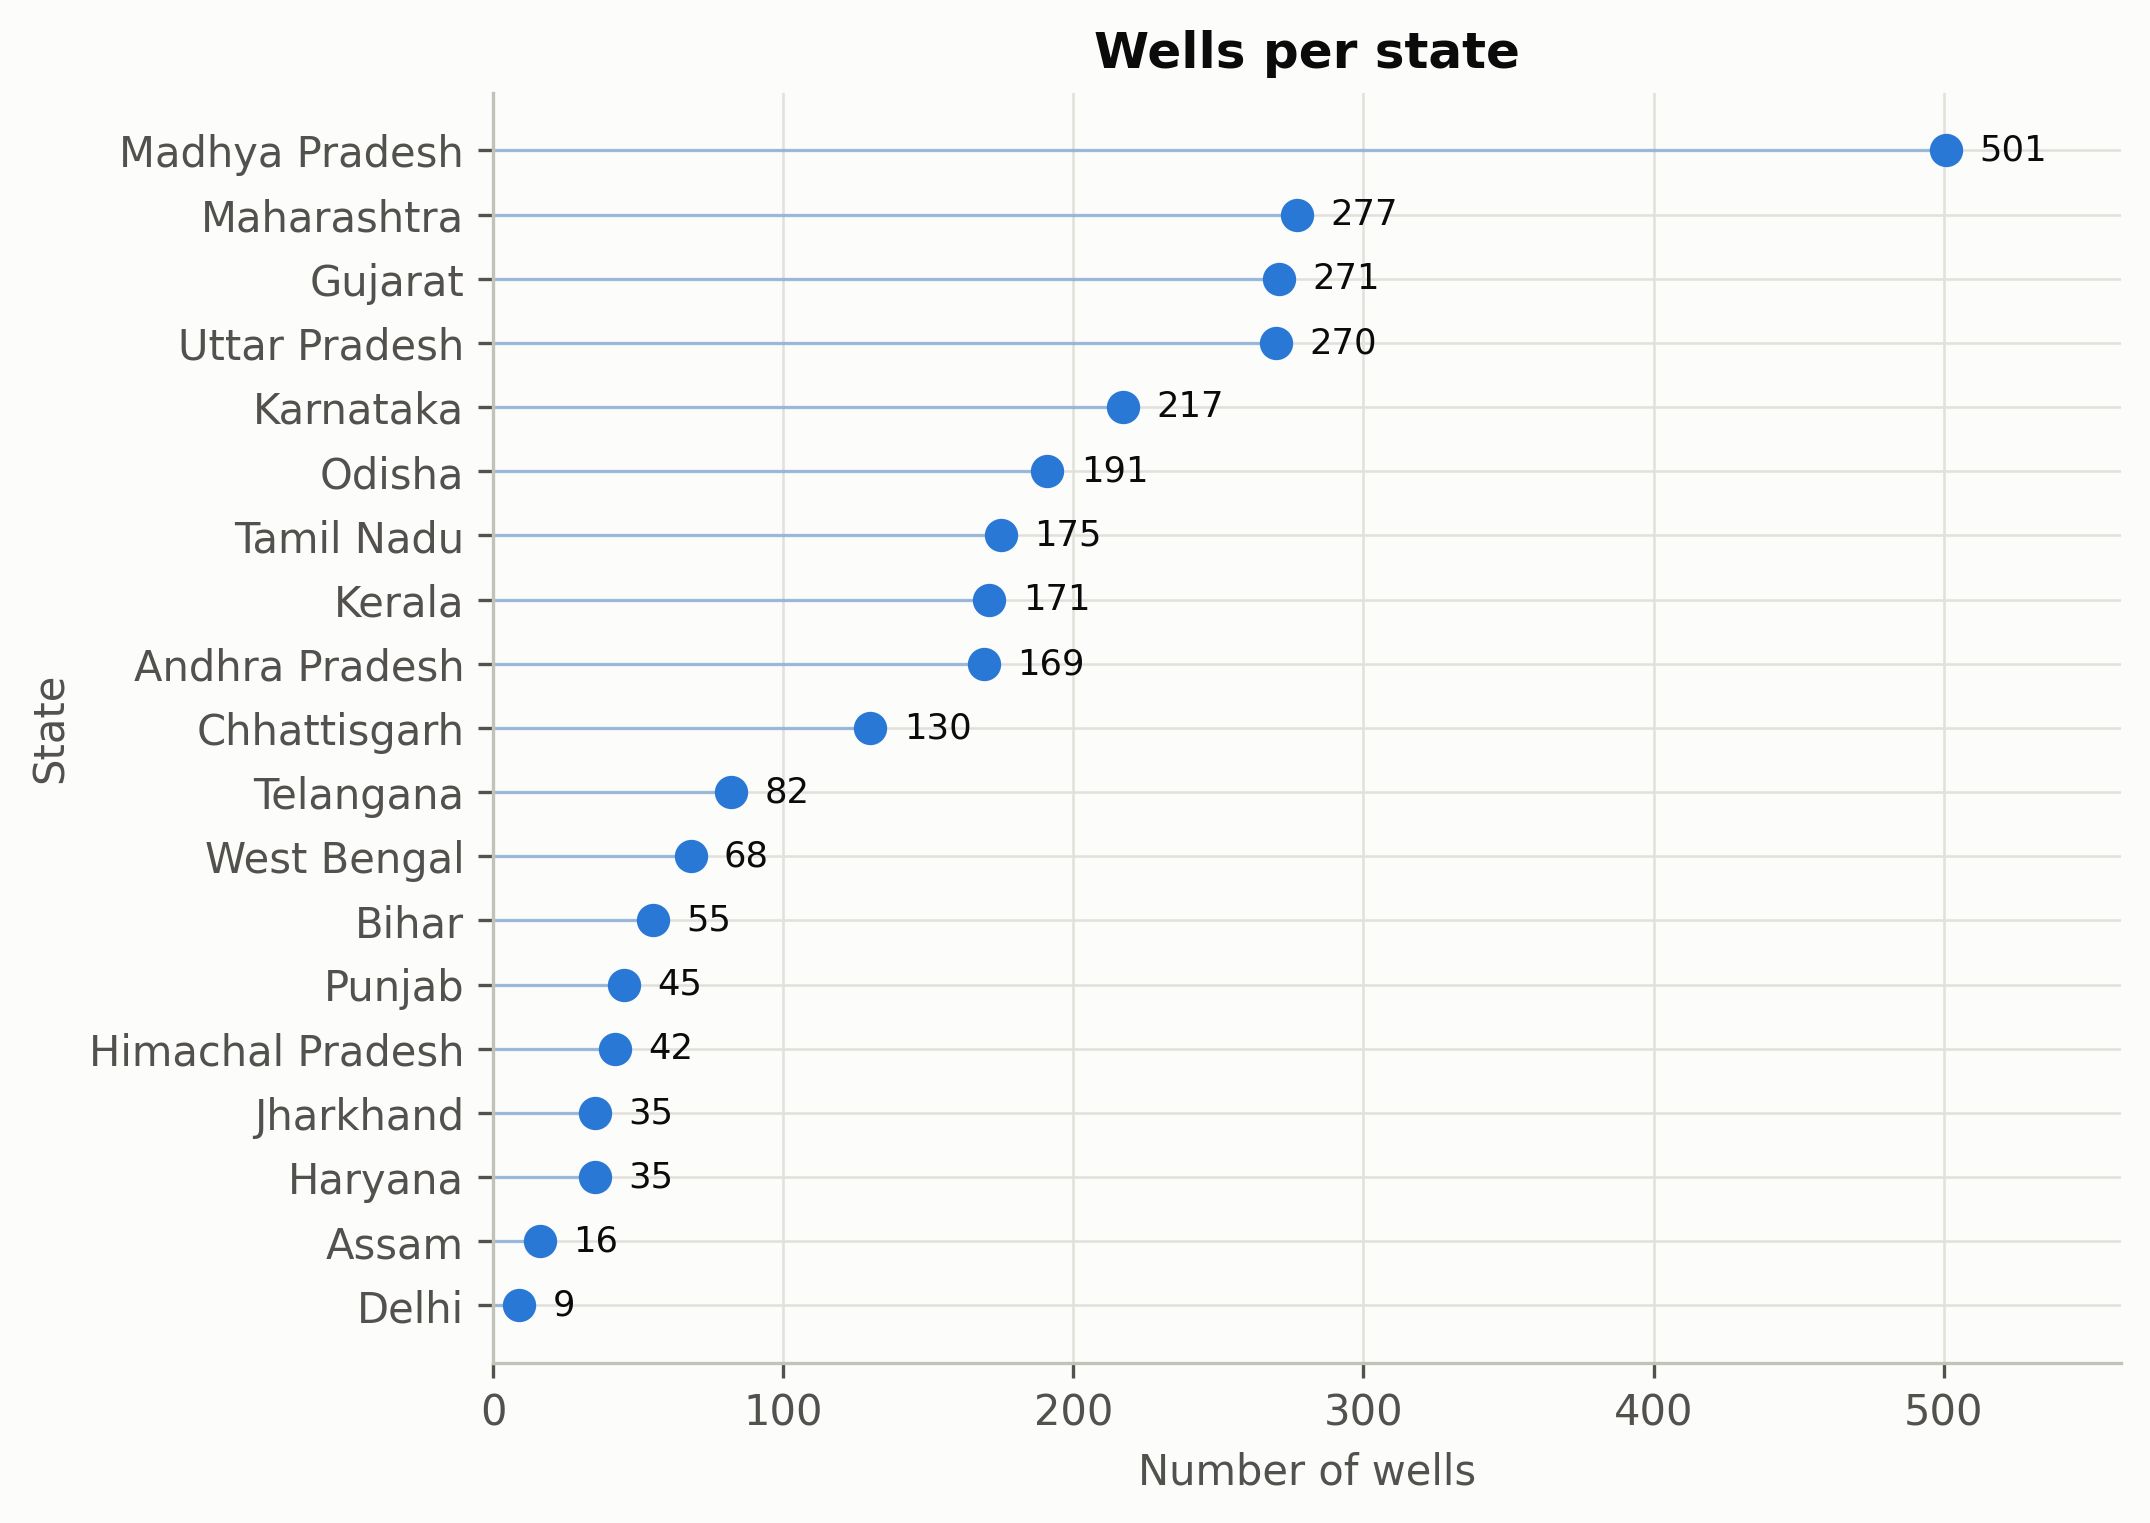

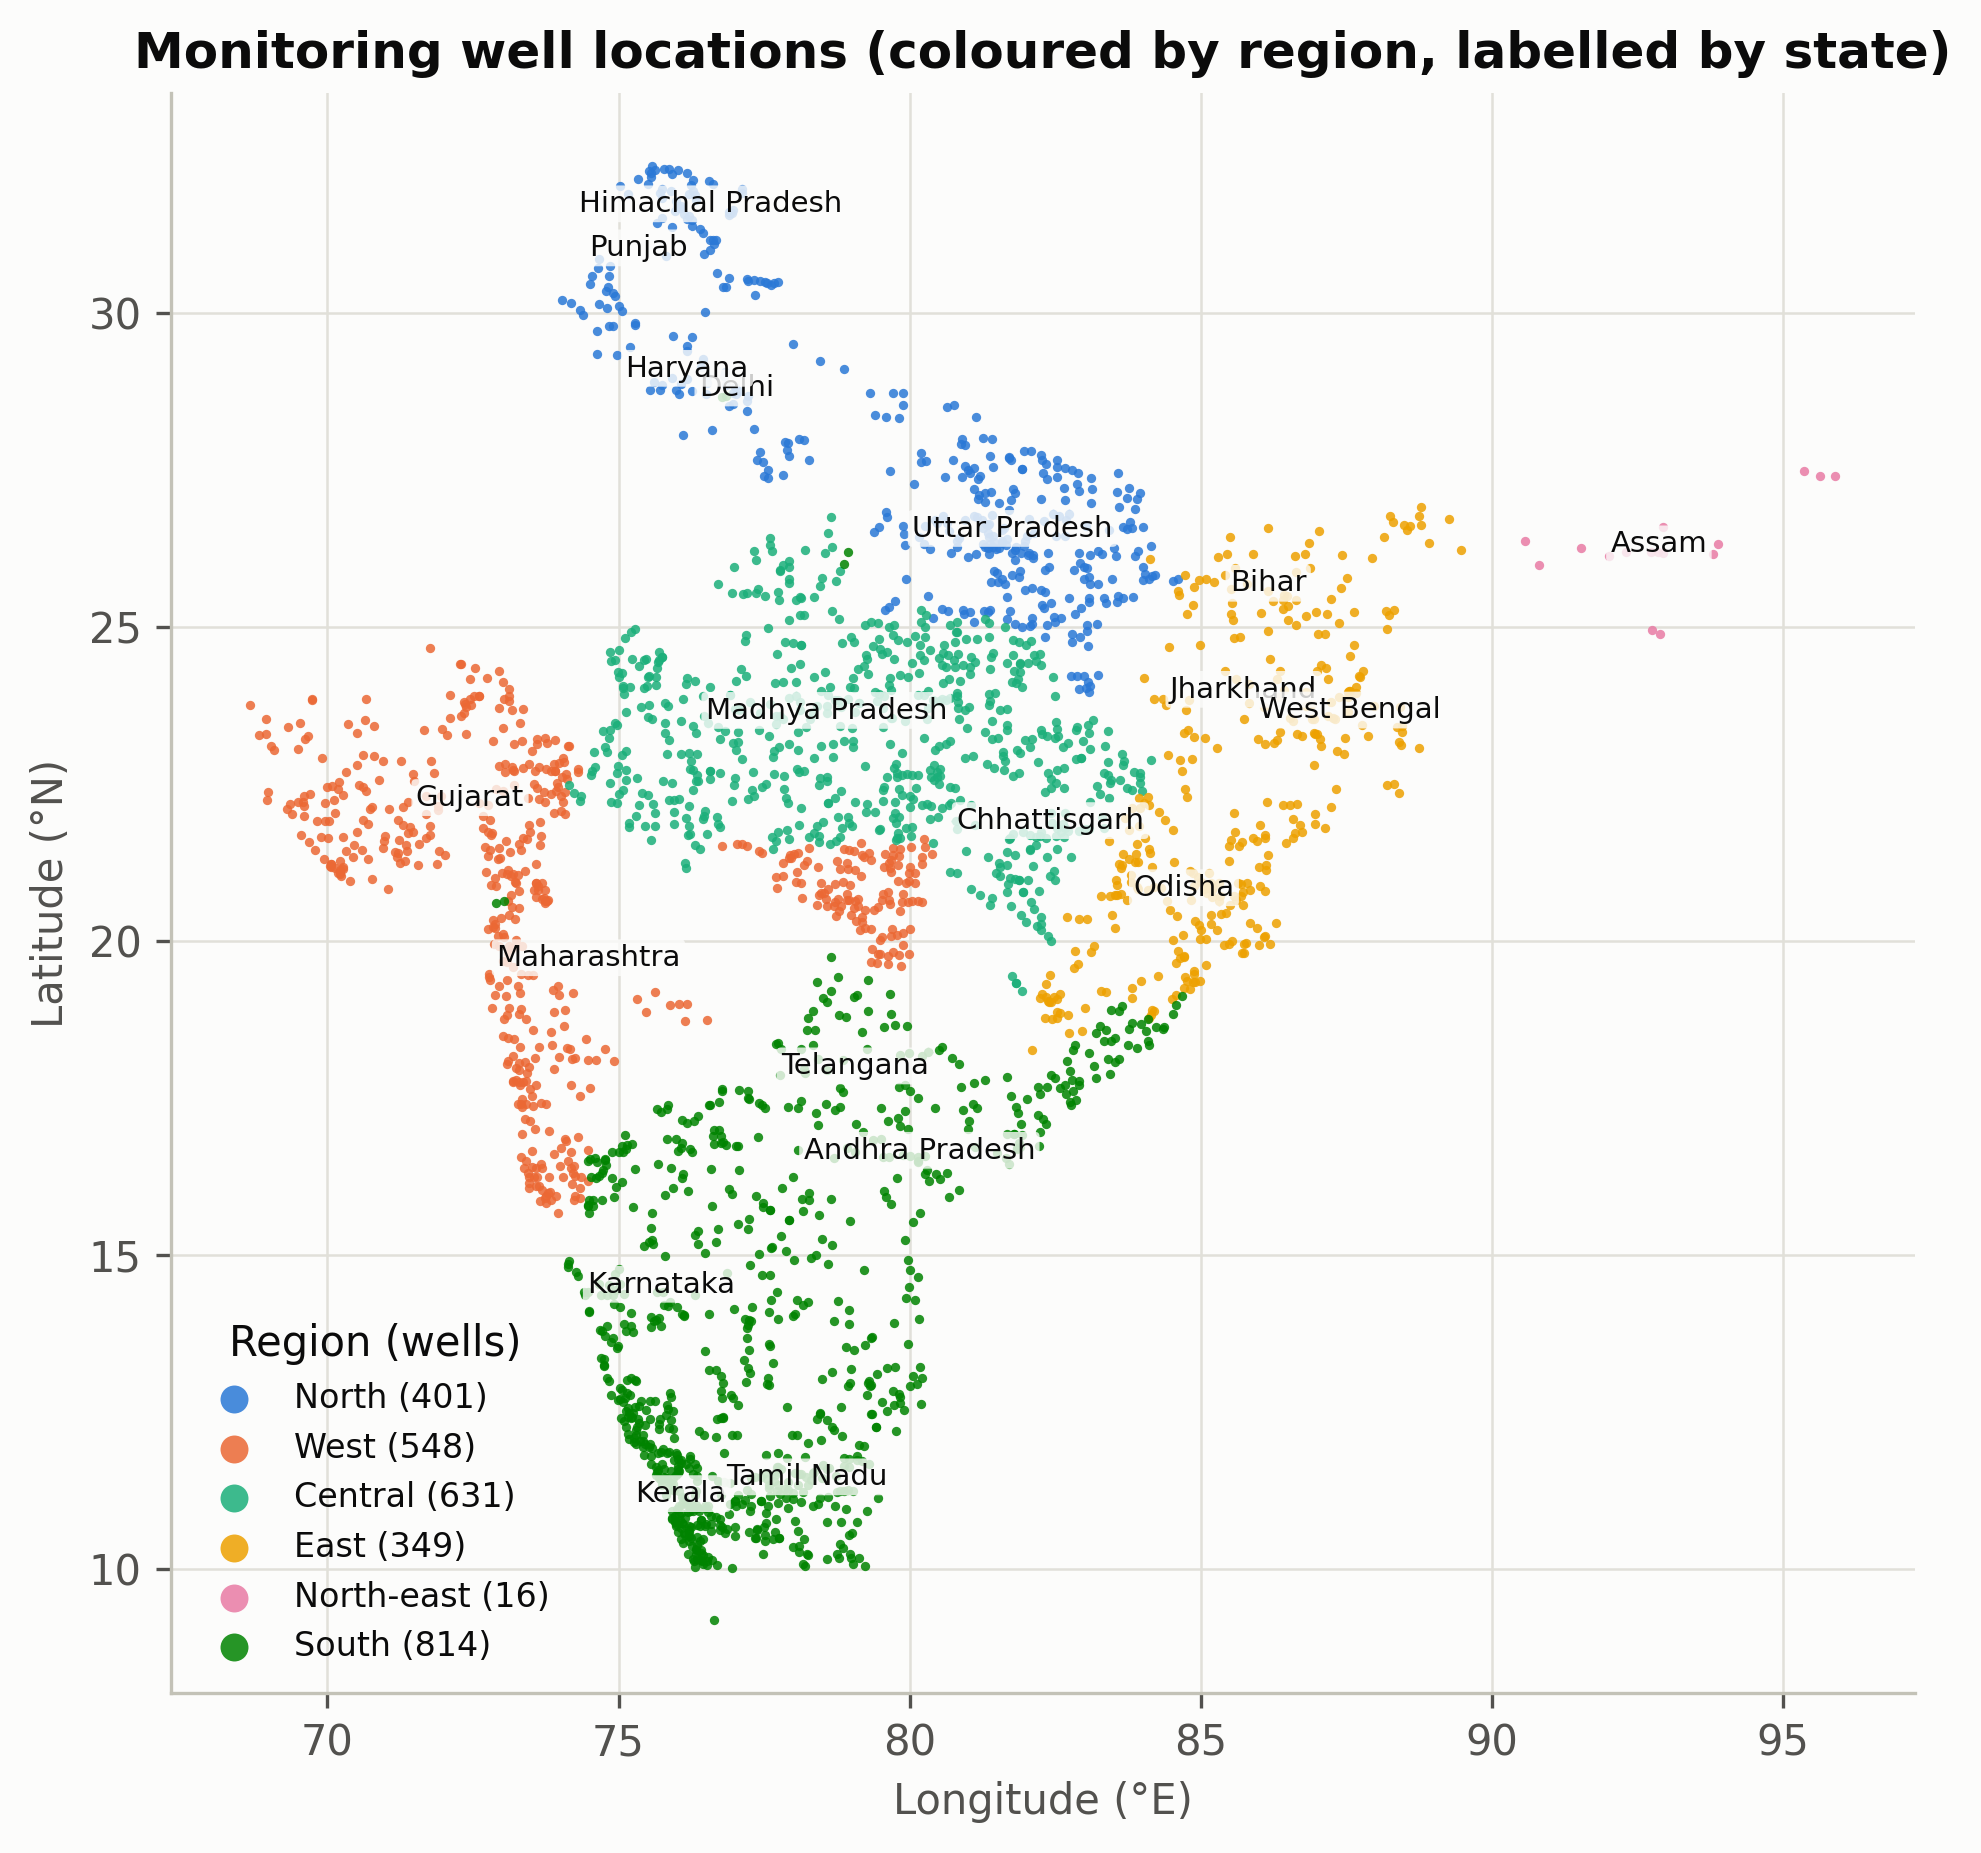

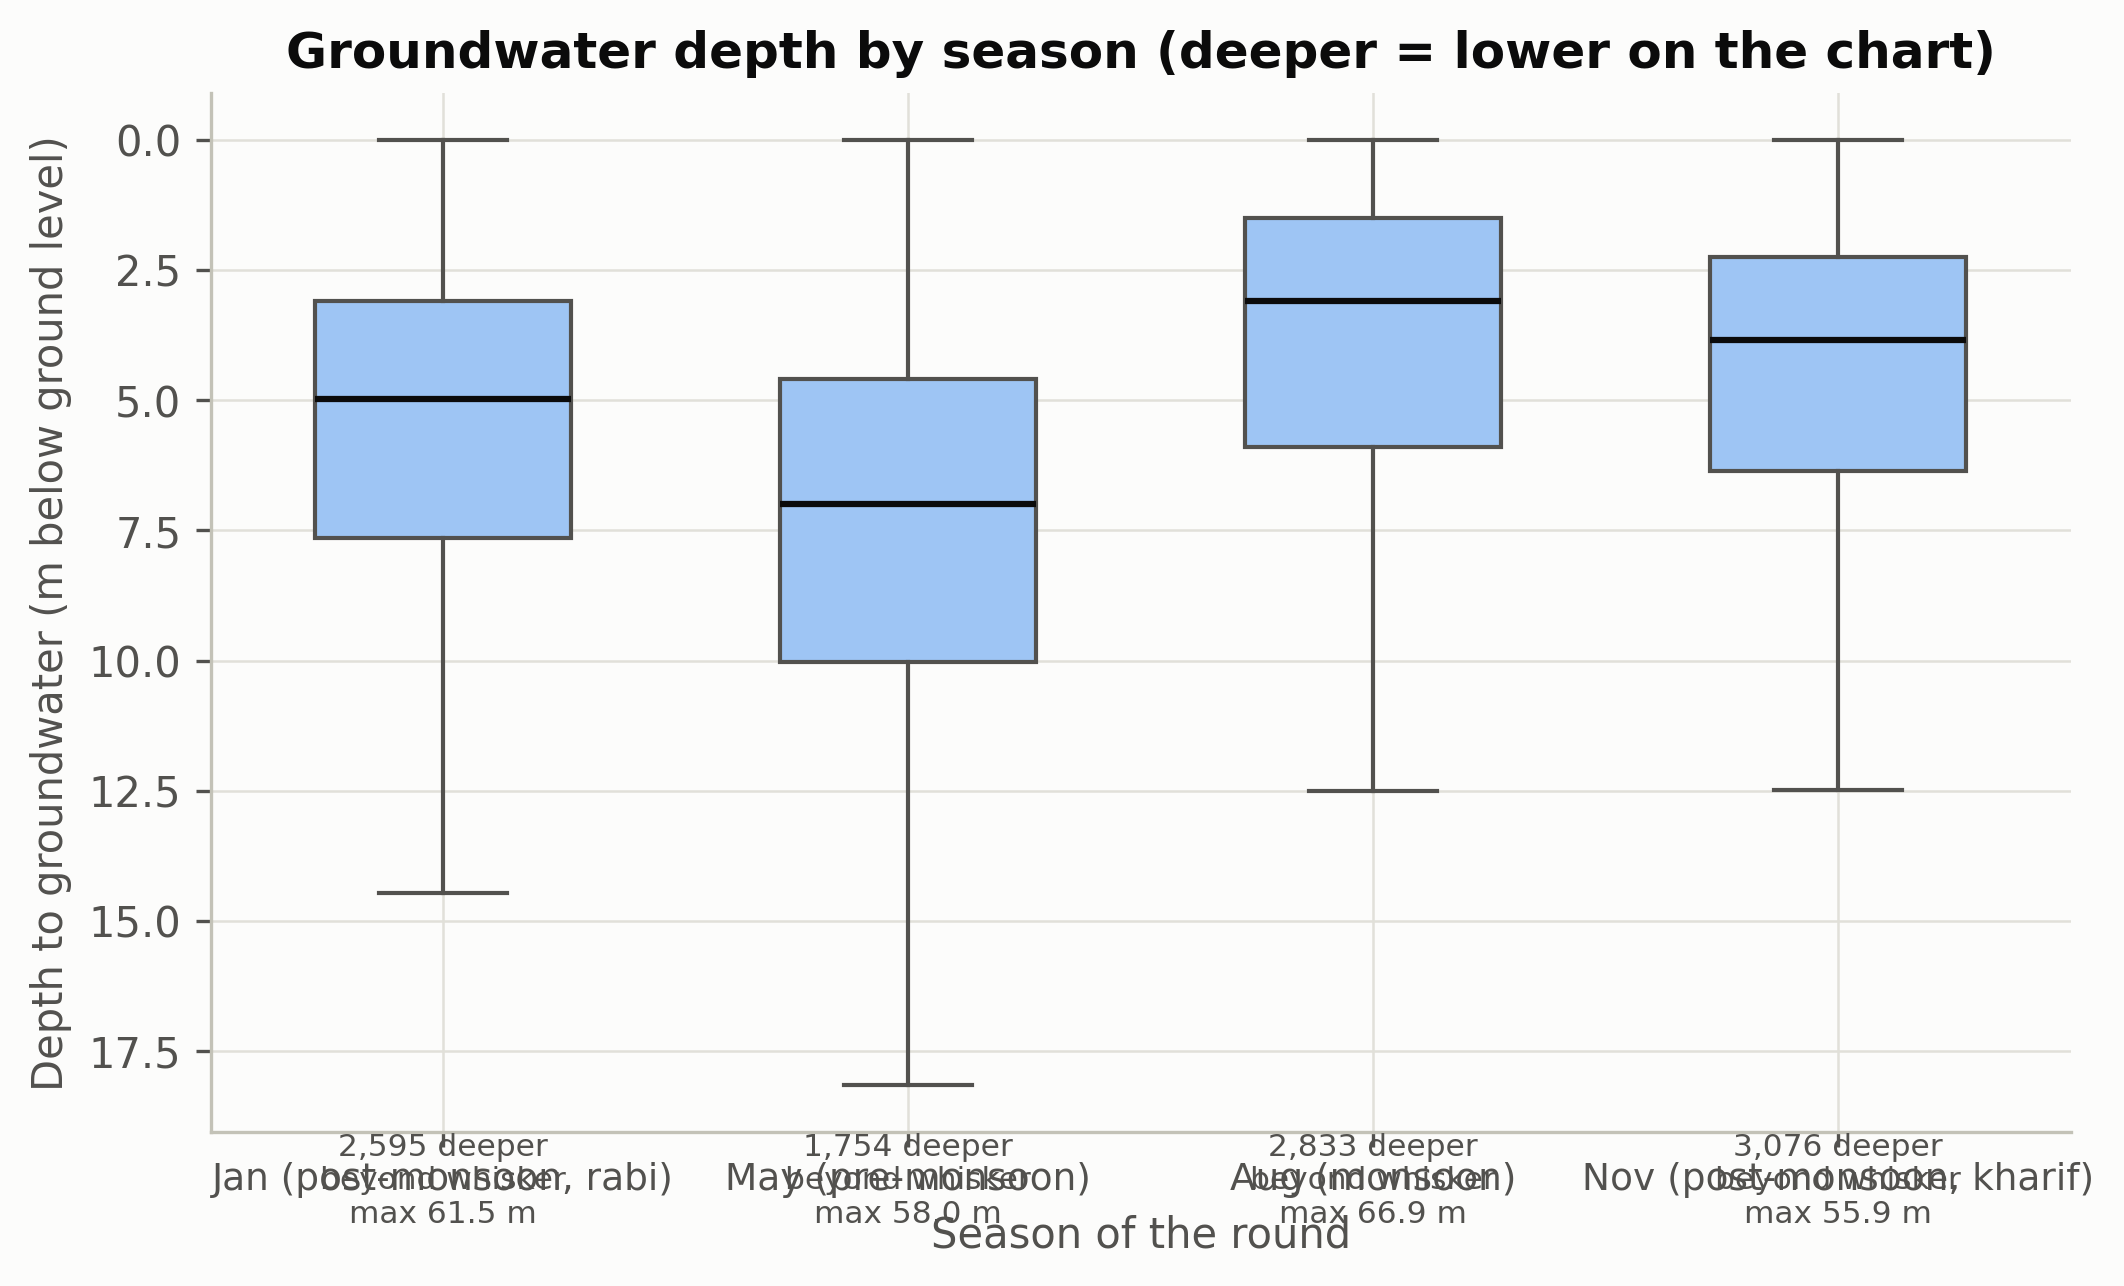

PASS  table has 253,828 rows and 2,759 wells


In [4]:
cols = ["well_id", "state", "district", "season", "year", "month", "date", "period_label", "station_name", "gwl_m_bgl", "rain_1m_mm",
        "baseline_mean_m", "baseline_std_m", "anomaly_z", "anomaly_z_capped", "stress_category", "stress_tadj", "stress_roll10"]
m = pd.read_parquet(ROOT / "processed" / "gw_features_by_state", columns=cols)
m["state"] = m.state.astype(str)
kpi = pd.DataFrame({"Item": ["Well-round rows (2,759 wells x 92 rounds)", "Wells", "States / districts", "Rounds per year x years", "Rows with a reading", "Missing readings",
                             "Rows with a rainfall value (CHIRPS, month before the round)"],
                    "Value": [f"{len(m):,}", f"{m.well_id.nunique():,}", f"{m.state.nunique()} / {m.district.nunique()}", "4 x 23 (2000-2022)", f"{int(m.gwl_m_bgl.notna().sum()):,}",
                              f"{100 * m.gwl_m_bgl.isna().mean():.2f}%", f"{int(m.rain_1m_mm.notna().sum()):,}"]})
display(kpi)
wells = m.drop_duplicates("well_id").groupby("state").size().sort_values(ascending=False)
pic(FIGS / "fig04_wells_per_state.png", 760)        # lollipop: wells per state
pic(FIGS / "fig05_well_locations.png", 640)         # map of the monitoring wells
pic(FIGS / "fig06_depth_by_season.png", 800)        # box plot: depth by season
check("table has 253,828 rows and 2,759 wells", len(m) == 253828 and m.well_id.nunique() == 2759)

## 2 · Architecture and the proposed model (slides: Proposed Model, Overall System Architecture)
**TGT-M = GRU-D + Temporal Fusion Transformer parts.** GRU-D reads the reading sequence and handles gaps with a mask and time-since-last-reading decay (no imputation). The TFT parts are a variable-selection network, gated residual networks, static enrichment and interpretable attention. The outputs are the median anomaly and the 10% and 90% quantiles.

fig_arch_system.png


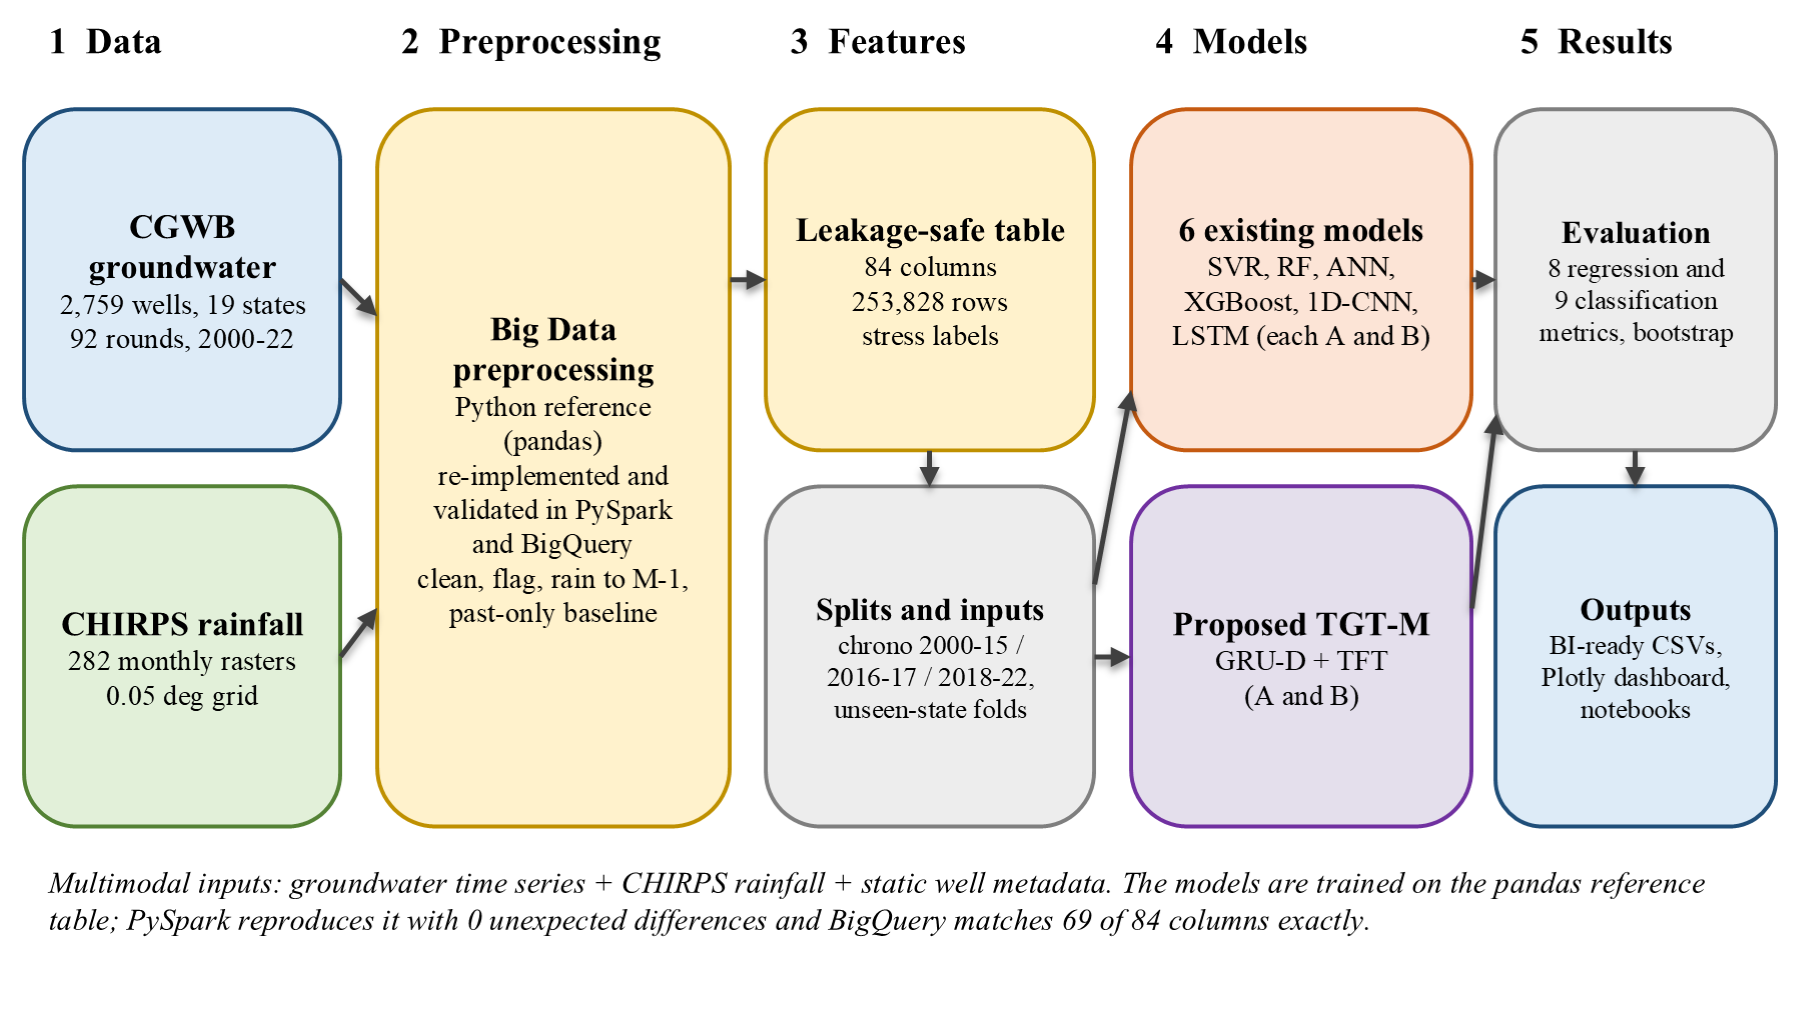

fig_tgtm.png


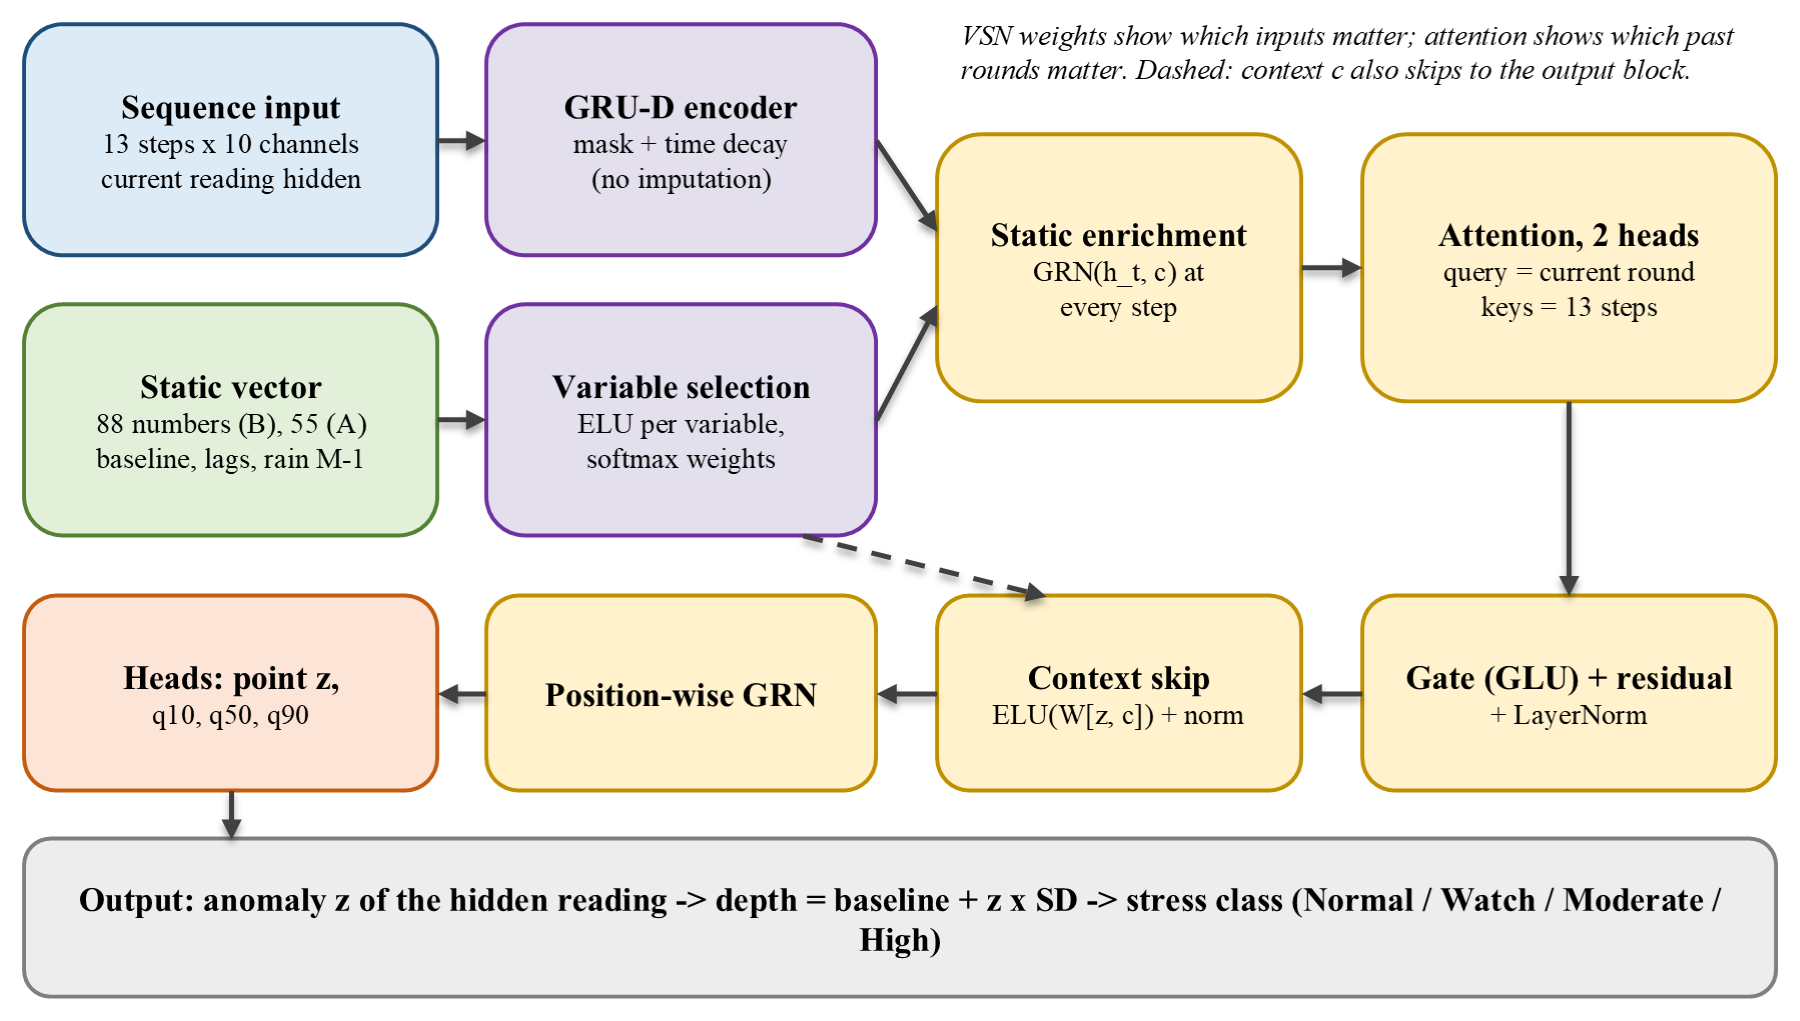

In [5]:
ASSETS = ROOT / "notebooks" / "assets"
for f in ("fig_arch_system.png", "fig_tgtm.png"):
    if (ASSETS / f).exists():
        print(f); display(Image(filename=str(ASSETS / f), width=900))

**Check the diagram against the code.** We build the real model, run one batch through it and record the output shape of every block with forward hooks. The order below is exactly the arrows of the TGT-M diagram. (Section 5 shows the model source code.)

input sequence: (8, 13, 10) (8 rows x 13 steps x 10 channels) | static vector: (8, 88) | config: {'hidden': 48, 'drop': 0.3, 'heads': 2}


,Block (diagram order),Output shape (batch of 8),Note,Parameters
0,1 GRU-D encoder (sequence),"(8, 13, 48)",one hidden state per step,8738
1,2 Variable selection -> context c,"(8, 48)",softmax weights over the static inputs,26536
2,3 Static enrichment GRN,"(8, 13, 48)",context c added to every step,11808
3,"4 Attention, 2 heads","(8, 1, 48)",query = current round,9408
4,"5 Gate (GLU), residual + LayerNorm","(8, 48)",gated skip,4704
5,6 Context skip,"(8, 48)","ELU(W[z, c]) + norm",4656
6,7 Position-wise GRN,"(8, 48)",final gated block,9504
7,8 Output heads,"(8, 4)","point, q10, q50, q90",196


total parameters: 75,646   (the study's chosen Model B configuration has 75,646)


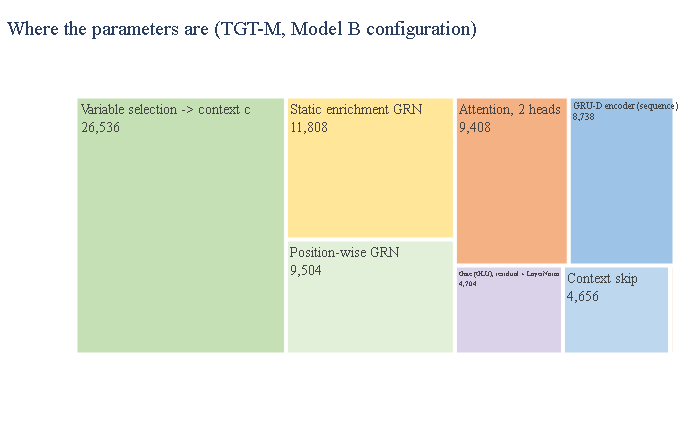

PASS  TGT-M outputs a point value and 3 quantiles per row
PASS  attention: current round attends over the 13 steps
PASS  model inputs: 88 numbers with rainfall (B), 55 without (A)


In [6]:
import data as D, lib as Lb, nets as N
b = D.build(); meta = b["meta"]
tr = (meta.split_chrono == "train").to_numpy(); va = (meta.split_chrono == "val").to_numpy(); te = (meta.split_chrono == "test").to_numpy()
Bq, Aq = Lb.Bundle(b, True, tr), Lb.Bundle(b, False, tr)
cfg = Lb.GRIDS["TGT-M"][2]
net = N.NETS["TGT-M"](n_static=Bq.X.shape[1], rain_idx=np.flatnonzero(Bq.is_rain), **cfg["arch"]).eval()
stages = [("1  GRU-D encoder (sequence)", net.enc, "one hidden state per step"), ("2  Variable selection -> context c", net.vsn, "softmax weights over the static inputs"),
          ("3  Static enrichment GRN", net.enrich, "context c added to every step"), ("4  Attention, 2 heads", net.attn, "query = current round"),
          ("5  Gate (GLU), residual + LayerNorm", net.gate, "gated skip"), ("6  Context skip", net.mix, "ELU(W[z, c]) + norm"),
          ("7  Position-wise GRN", net.pos, "final gated block"), ("8  Output heads", net.out, "point, q10, q50, q90")]
shape = {}
def hook(name):
    def f(mod, inp, out):
        shape[name] = tuple((out[0] if isinstance(out, tuple) else out).shape)
    return f
for name, mod, _ in stages:
    mod.register_forward_hook(hook(name))
seq, st = torch.from_numpy(Bq.seq[:8]), torch.from_numpy(Bq.X[:8])
with torch.no_grad():
    point, q = net(seq, st, return_all=True)
tab = pd.DataFrame([[n, str(shape[n]), note, sum(p.numel() for p in mod.parameters())] for n, mod, note in stages], columns=["Block (diagram order)", "Output shape (batch of 8)", "Note", "Parameters"])
print("input sequence:", tuple(seq.shape), "(8 rows x 13 steps x 10 channels) | static vector:", tuple(st.shape), "| config:", cfg["arch"])
display(tab)
total = sum(p.numel() for p in net.parameters())
print(f"total parameters: {total:,}   (the study's chosen Model B configuration has 75,646)")
fig = go.Figure(go.Treemap(labels=[s[3:] for s in tab["Block (diagram order)"]], parents=[""] * len(tab), values=list(tab["Parameters"]),
                         texttemplate="%{label}<br>%{value:,}", marker=dict(colors=["#9DC3E6", "#C5E0B4", "#FFE699", "#F4B183", "#D9D2E9", "#BDD7EE", "#E2F0D9", "#FBE5D6"])))
show(fig, "Where the parameters are (TGT-M, Model B configuration)", "", "", h=430)
check("TGT-M outputs a point value and 3 quantiles per row", tuple(point.shape) == (8,) and tuple(q.shape) == (8, 3))
check("attention: current round attends over the 13 steps", tuple(net.last_attn.shape) == (8, 1, 13))
check("model inputs: 88 numbers with rainfall (B), 55 without (A)", Bq.X.shape[1] == 88 and Aq.X.shape[1] == 55)

## 3 · Preprocessing with Apache Spark (slide: Preprocessing, Big Data analysis)
The reference pipeline (pandas) was re-implemented in **PySpark** (branch `spark-first-preprocessing`: 0 unexpected differences on all 253,828 x 84 values) and in BigQuery SQL. Here Spark **recomputes the key step live**: for every well and season, the baseline mean and SD of the *earlier* readings only (window `UNBOUNDED PRECEDING` to `1 PRECEDING`, at least 5), then the anomaly z = (reading - mean) / max(SD, 0.10 m), clipped at +/-5; it is compared with the pipeline's stored columns.

```python
w = Window.partitionBy("well_id", "season").orderBy("date").rowsBetween(Window.unboundedPreceding, -1)   # earlier readings only
df.withColumn("n", count("gwl_m_bgl").over(w)).withColumn("mu", avg("gwl_m_bgl").over(w)).withColumn("sd", stddev_samp("gwl_m_bgl").over(w))
```
Spark runs in `local[2]` mode on one machine: the pattern is shown, not a cluster-scale claim.

Spark cannot run on this operating system (exit code 2): showing the saved result of the same script (run on Linux).
Spark 3.5.3 on linux | 253,828 rows in 2 partitions | 17.4 s


,Comparison with the pipeline columns,Spark vs stored pipeline
0,Readings compared (at least 5 earlier same-sea...,"166,306"
1,Largest difference in baseline mean (m),0.00e+00
2,Largest difference in anomaly z,1.30e-11


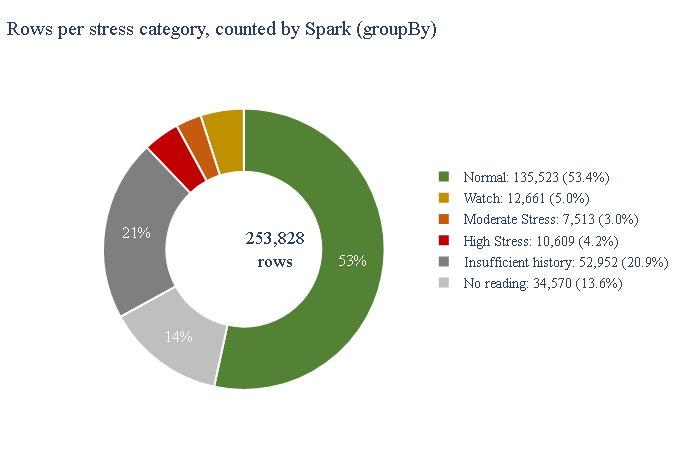

PASS  Spark baseline equals the pipeline baseline (max difference < 1e-6 m)
PASS  Spark anomaly z equals the pipeline z (max difference < 1e-6)


In [7]:
import subprocess
if importlib.util.find_spec("pyspark") is None and shutil.which("java"):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark==3.5.3"])
if importlib.util.find_spec("pyspark") is not None and shutil.which("java"):
    r = subprocess.run([sys.executable, str(ROOT / "modeling" / "spark_check.py")], capture_output=True, text=True)
    print("Spark run finished" if r.returncode == 0 else "Spark cannot run on this operating system (exit code %d): showing the saved result of the same script (run on Linux)." % r.returncode)
else:
    print("Java or pyspark not available in this session: showing the saved result of the same script (run on Linux).")
sp = json.load(open(T / "spark_check.json"))
print(f"Spark {sp['spark_version']} on {sp['platform']} | {sp['rows']:,} rows in {sp['partitions']} partitions | {sp['seconds']} s")
display(pd.DataFrame({"Comparison with the pipeline columns": ["Readings compared (at least 5 earlier same-season readings)", "Largest difference in baseline mean (m)", "Largest difference in anomaly z"],
                      "Spark vs stored pipeline": [f"{sp['rows_compared']:,}", f"{sp['max_abs_diff_baseline_mean_m']:.2e}", f"{sp['max_abs_diff_z']:.2e}"]}))
cnt = pd.Series(sp["stress_counts"]).reindex(["Normal", "Watch", "Moderate Stress", "High Stress", "Insufficient history", "No reading"])
tot = int(cnt.sum()); share = 100 * cnt / tot
fig = go.Figure(go.Pie(labels=[f"{k}: {v:,} ({s:.1f}%)" for k, v, s in zip(cnt.index, cnt.values, share)], values=list(cnt.values), hole=0.55, sort=False,
                      text=[f"{s:.0f}%" if s >= 10 else "" for s in share], textinfo="text", textposition="inside", insidetextorientation="horizontal",
                      textfont=dict(size=16, color="white"), domain=dict(x=[0.02, 0.55], y=[0.0, 0.88]),
                      marker=dict(colors=[PAL["G"], "#BF9000", PAL["B"], "#C00000", PAL["grey"], "#BFBFBF"], line=dict(color="white", width=2))))
fig.add_annotation(text=f"{tot:,}<br>rows", x=0.285, y=0.44, showarrow=False, font=dict(size=18))
show(fig, "Rows per stress category, counted by Spark (groupBy)", "", "", h=460, legend=dict(orientation="v", x=0.58, y=0.5, xanchor="left"))
check("Spark baseline equals the pipeline baseline (max difference < 1e-6 m)", sp["max_abs_diff_baseline_mean_m"] < 1e-6)
check("Spark anomaly z equals the pipeline z (max difference < 1e-6)", sp["max_abs_diff_z"] < 1e-6)

## 4 · Results of preprocessing (slides: Results of Preprocessing, Preprocessing Metrics before vs after)

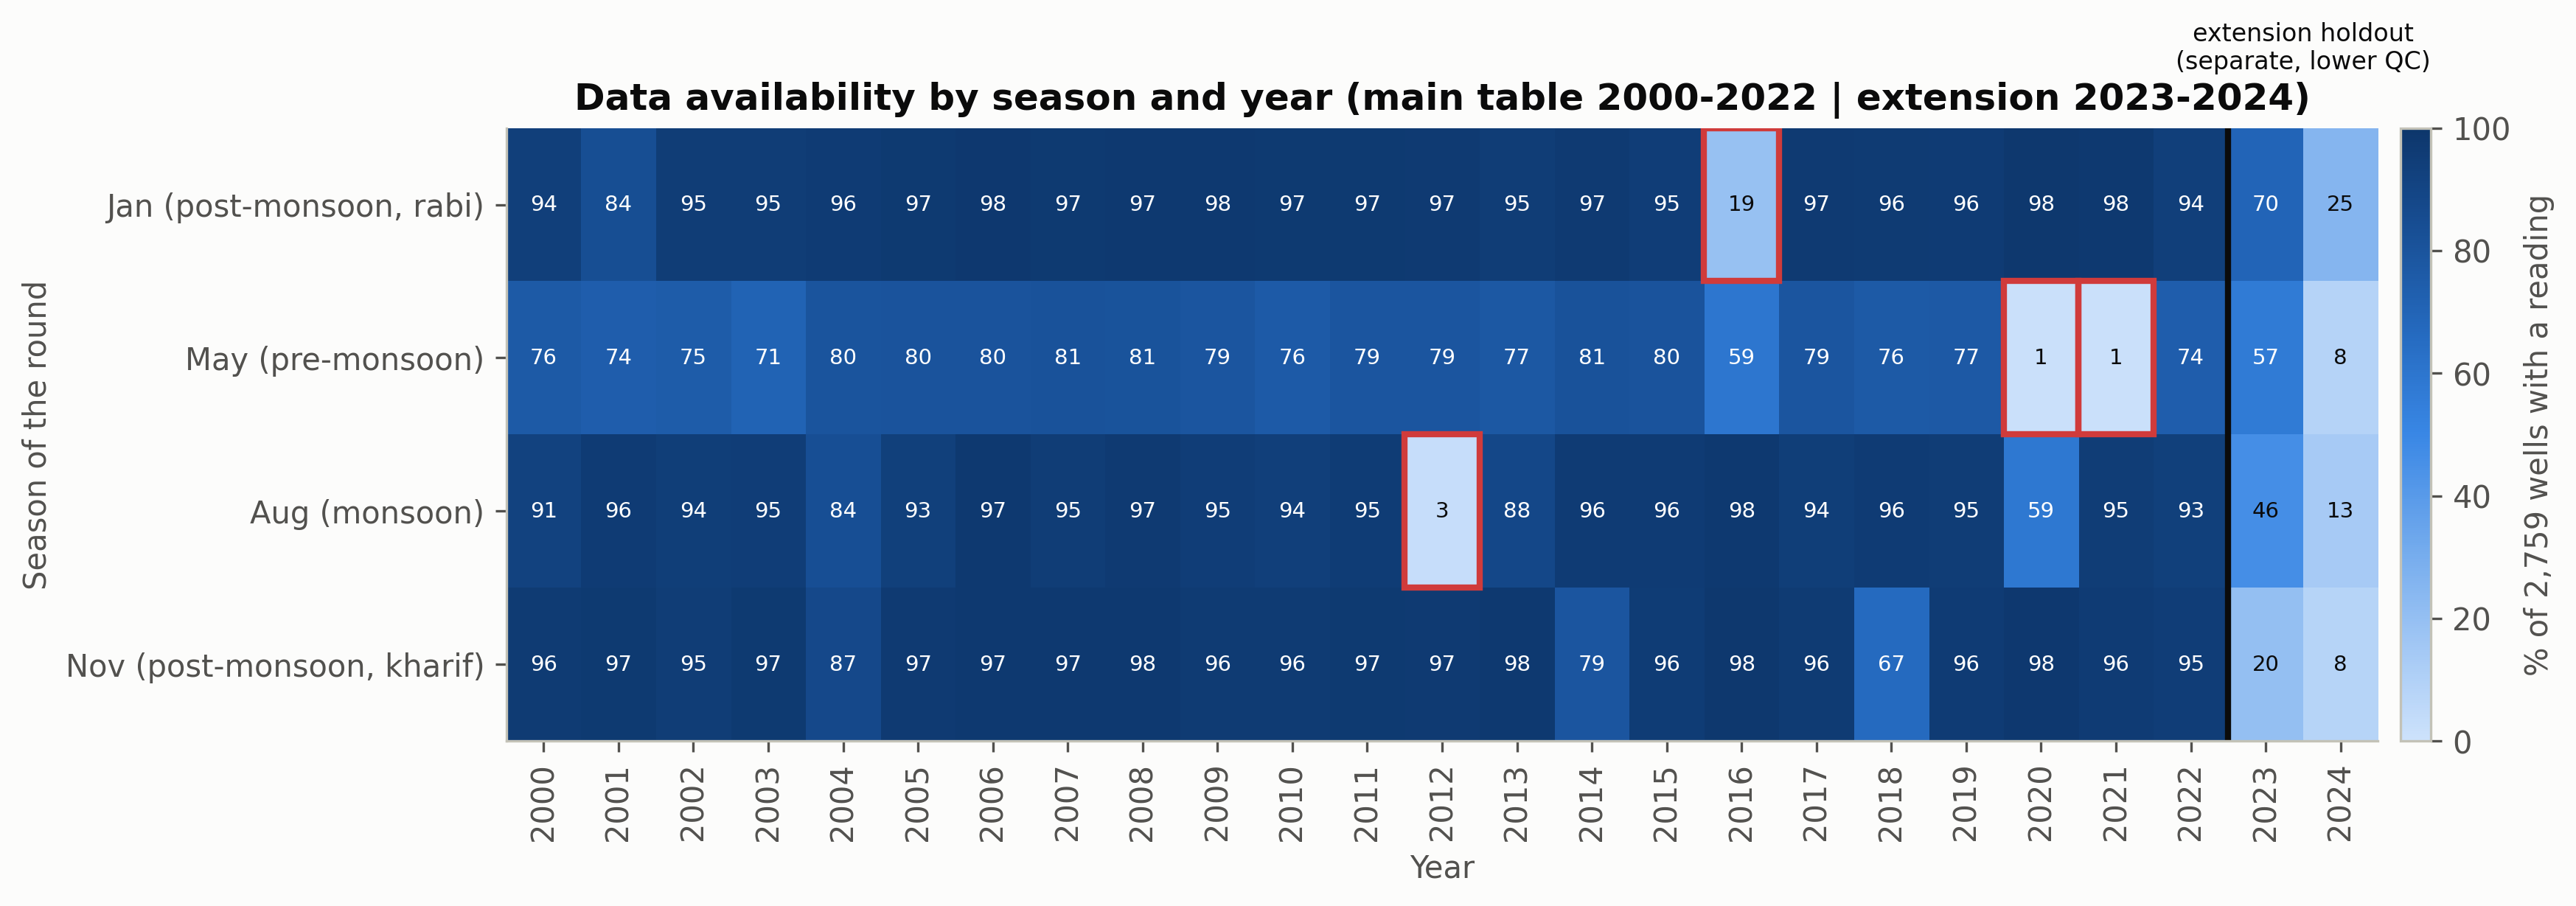

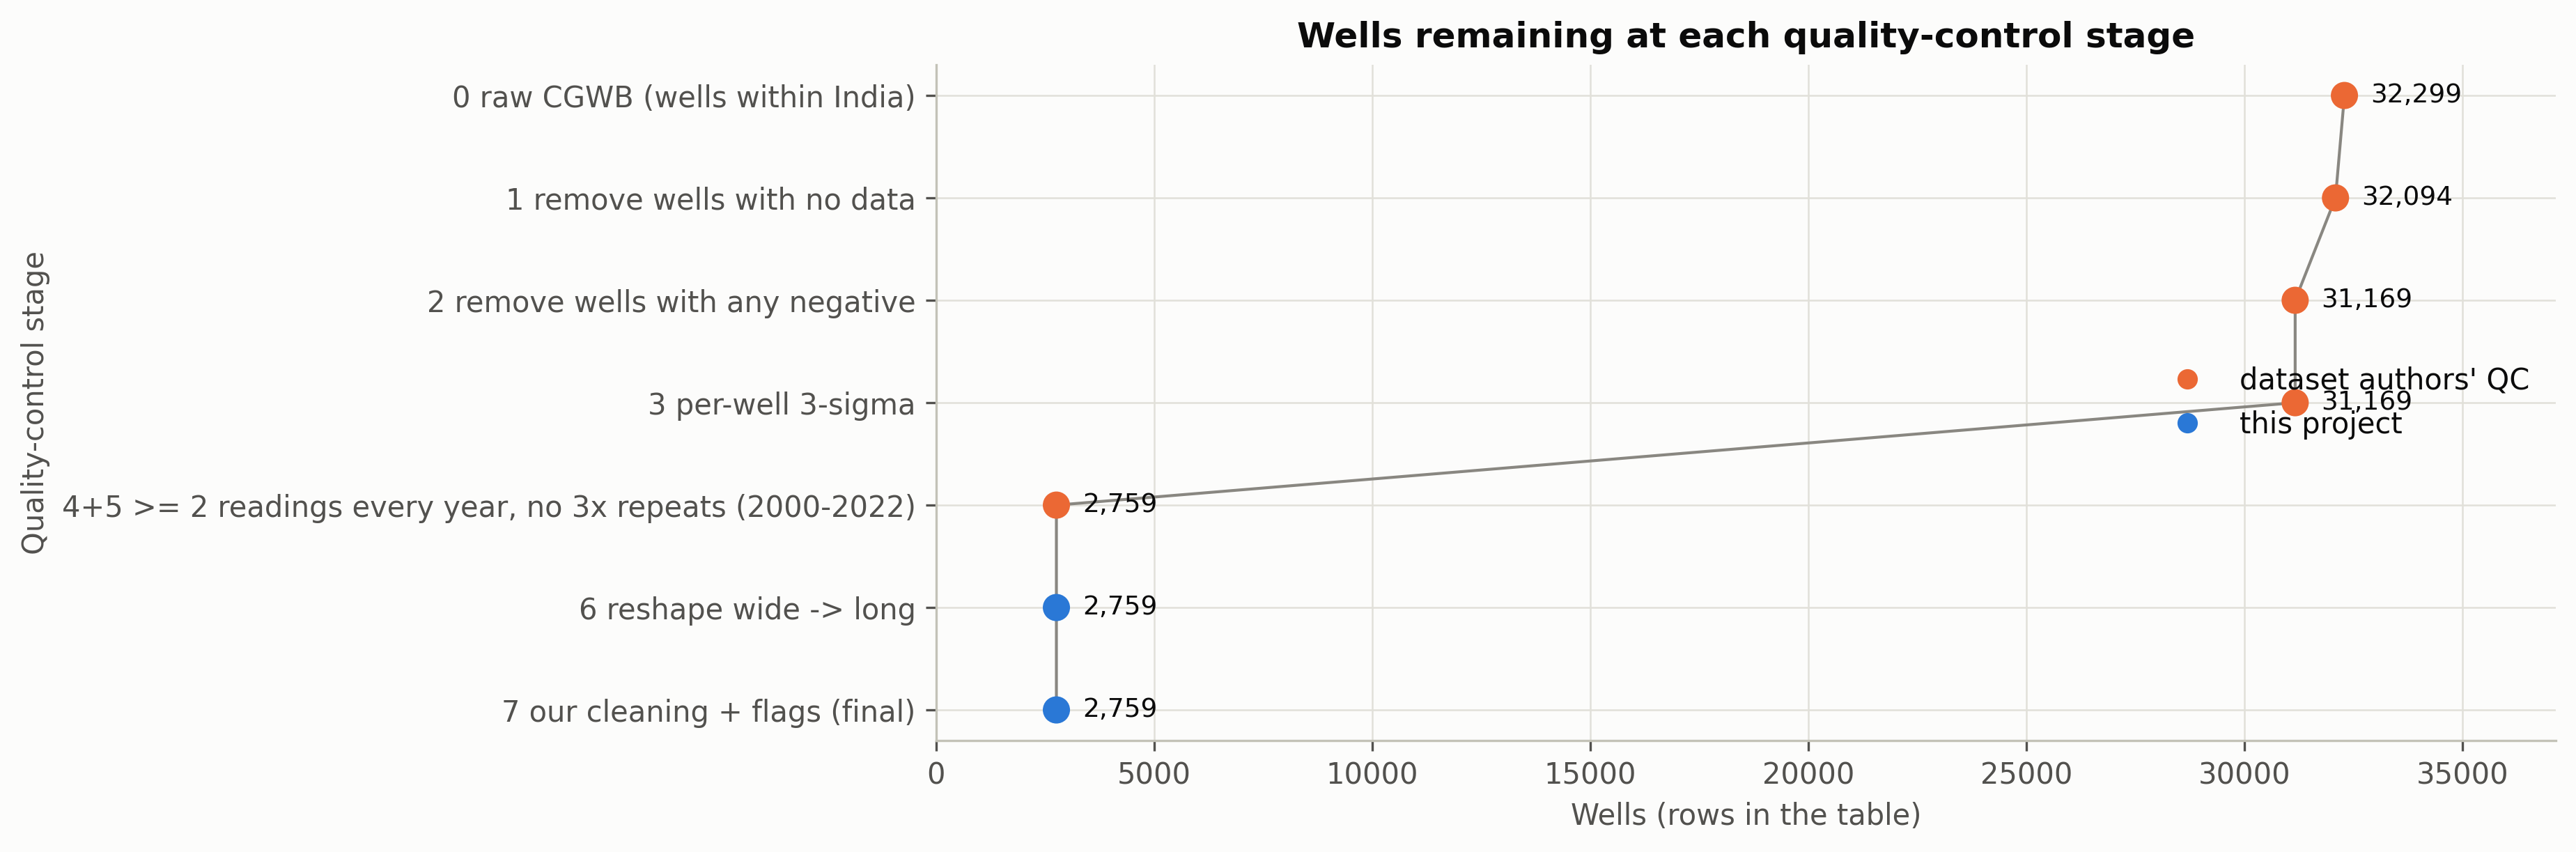

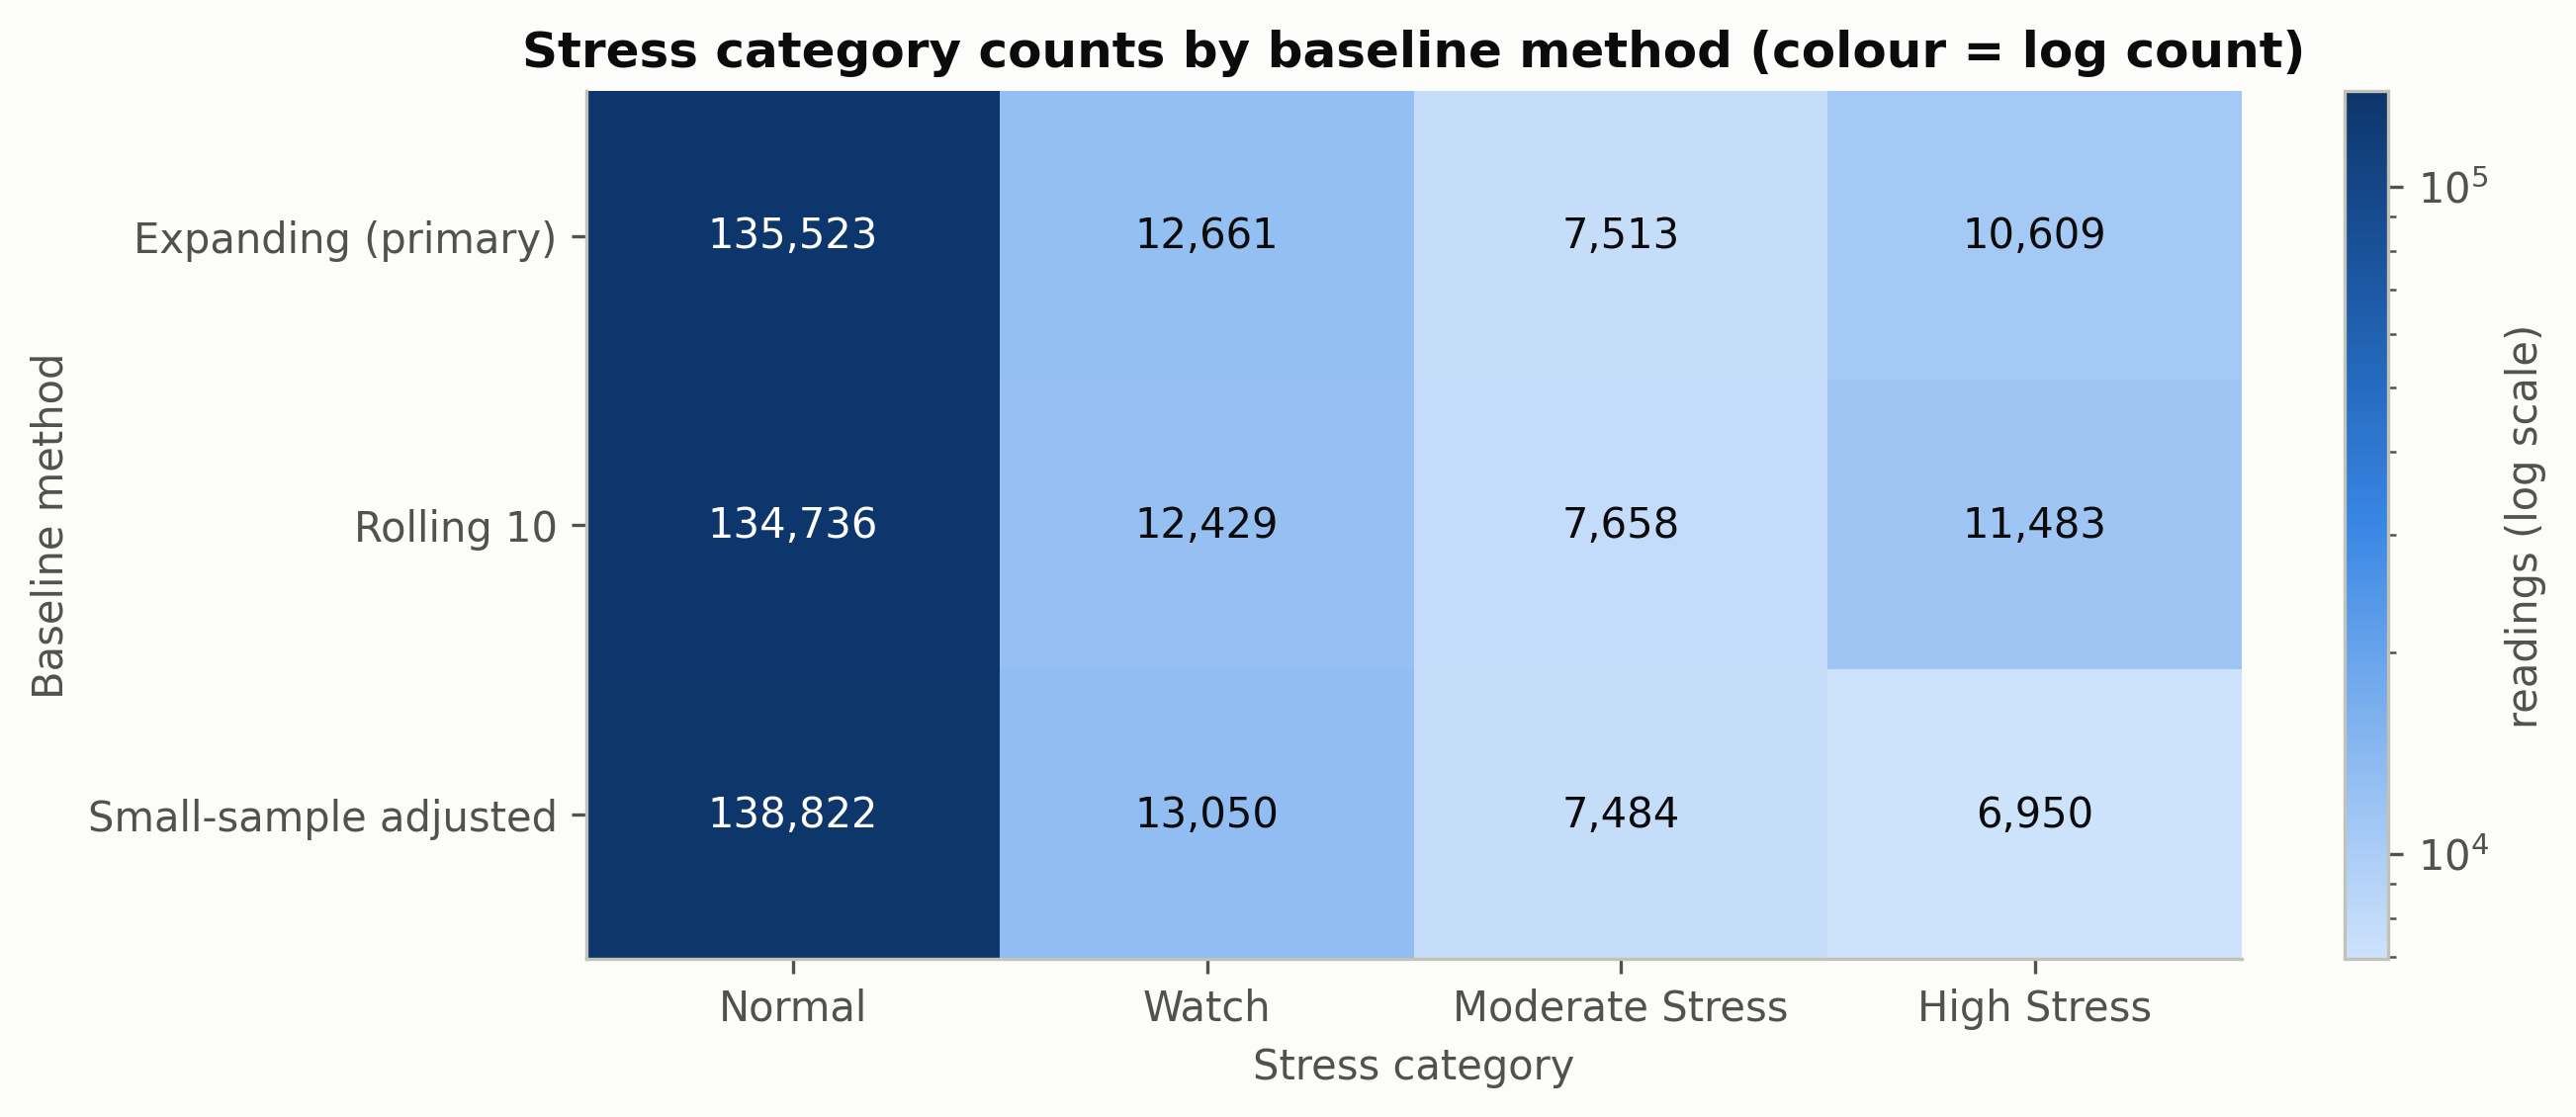

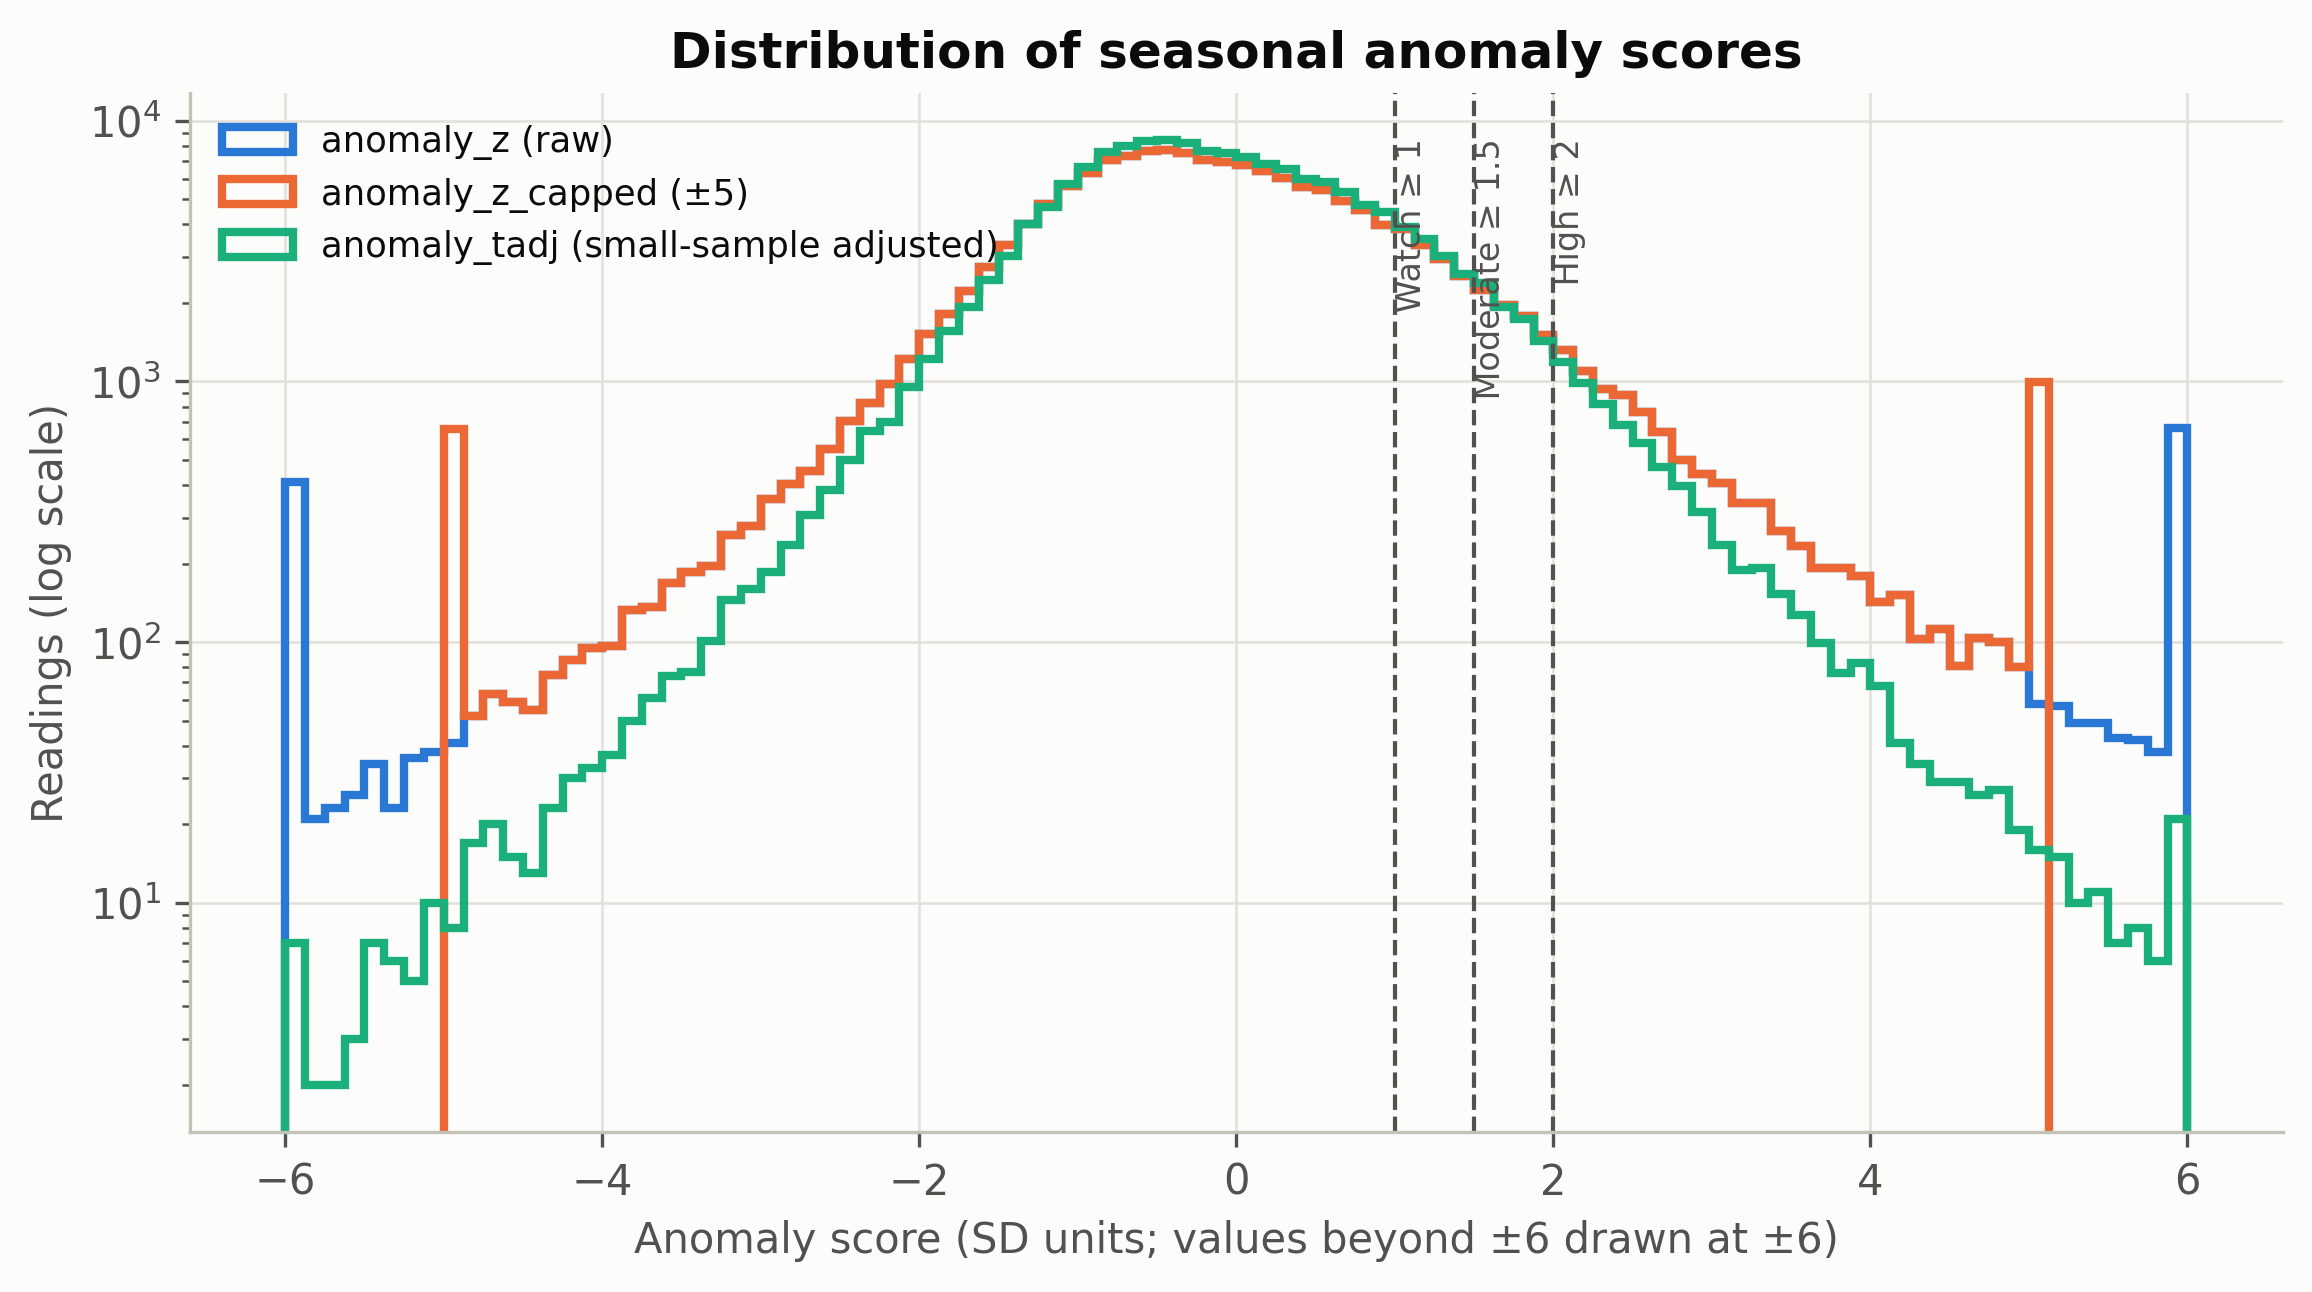

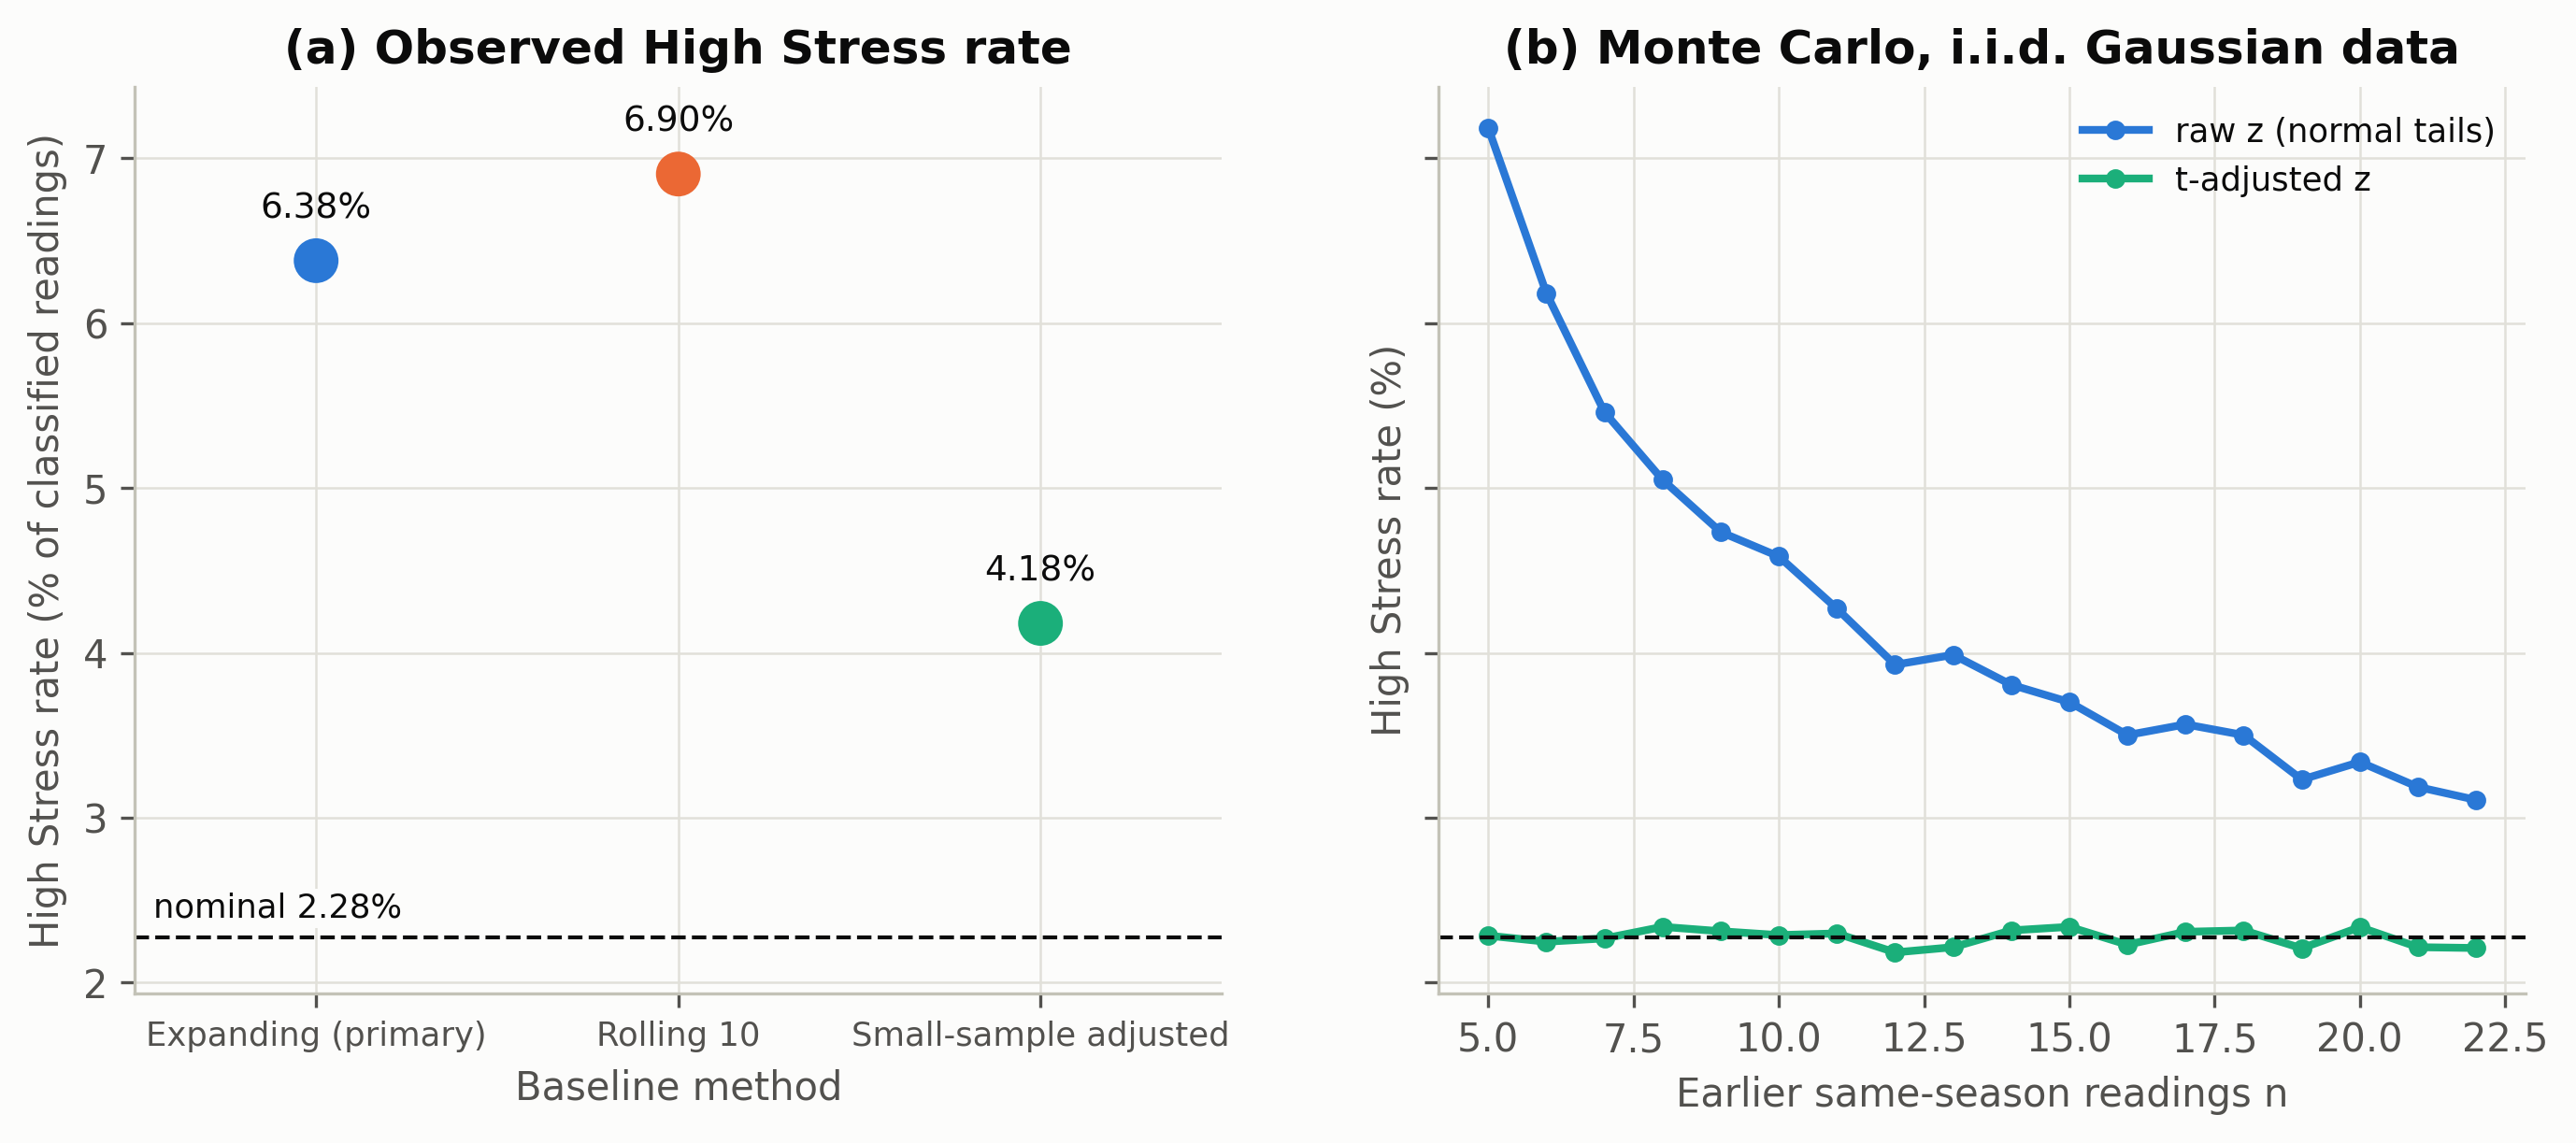

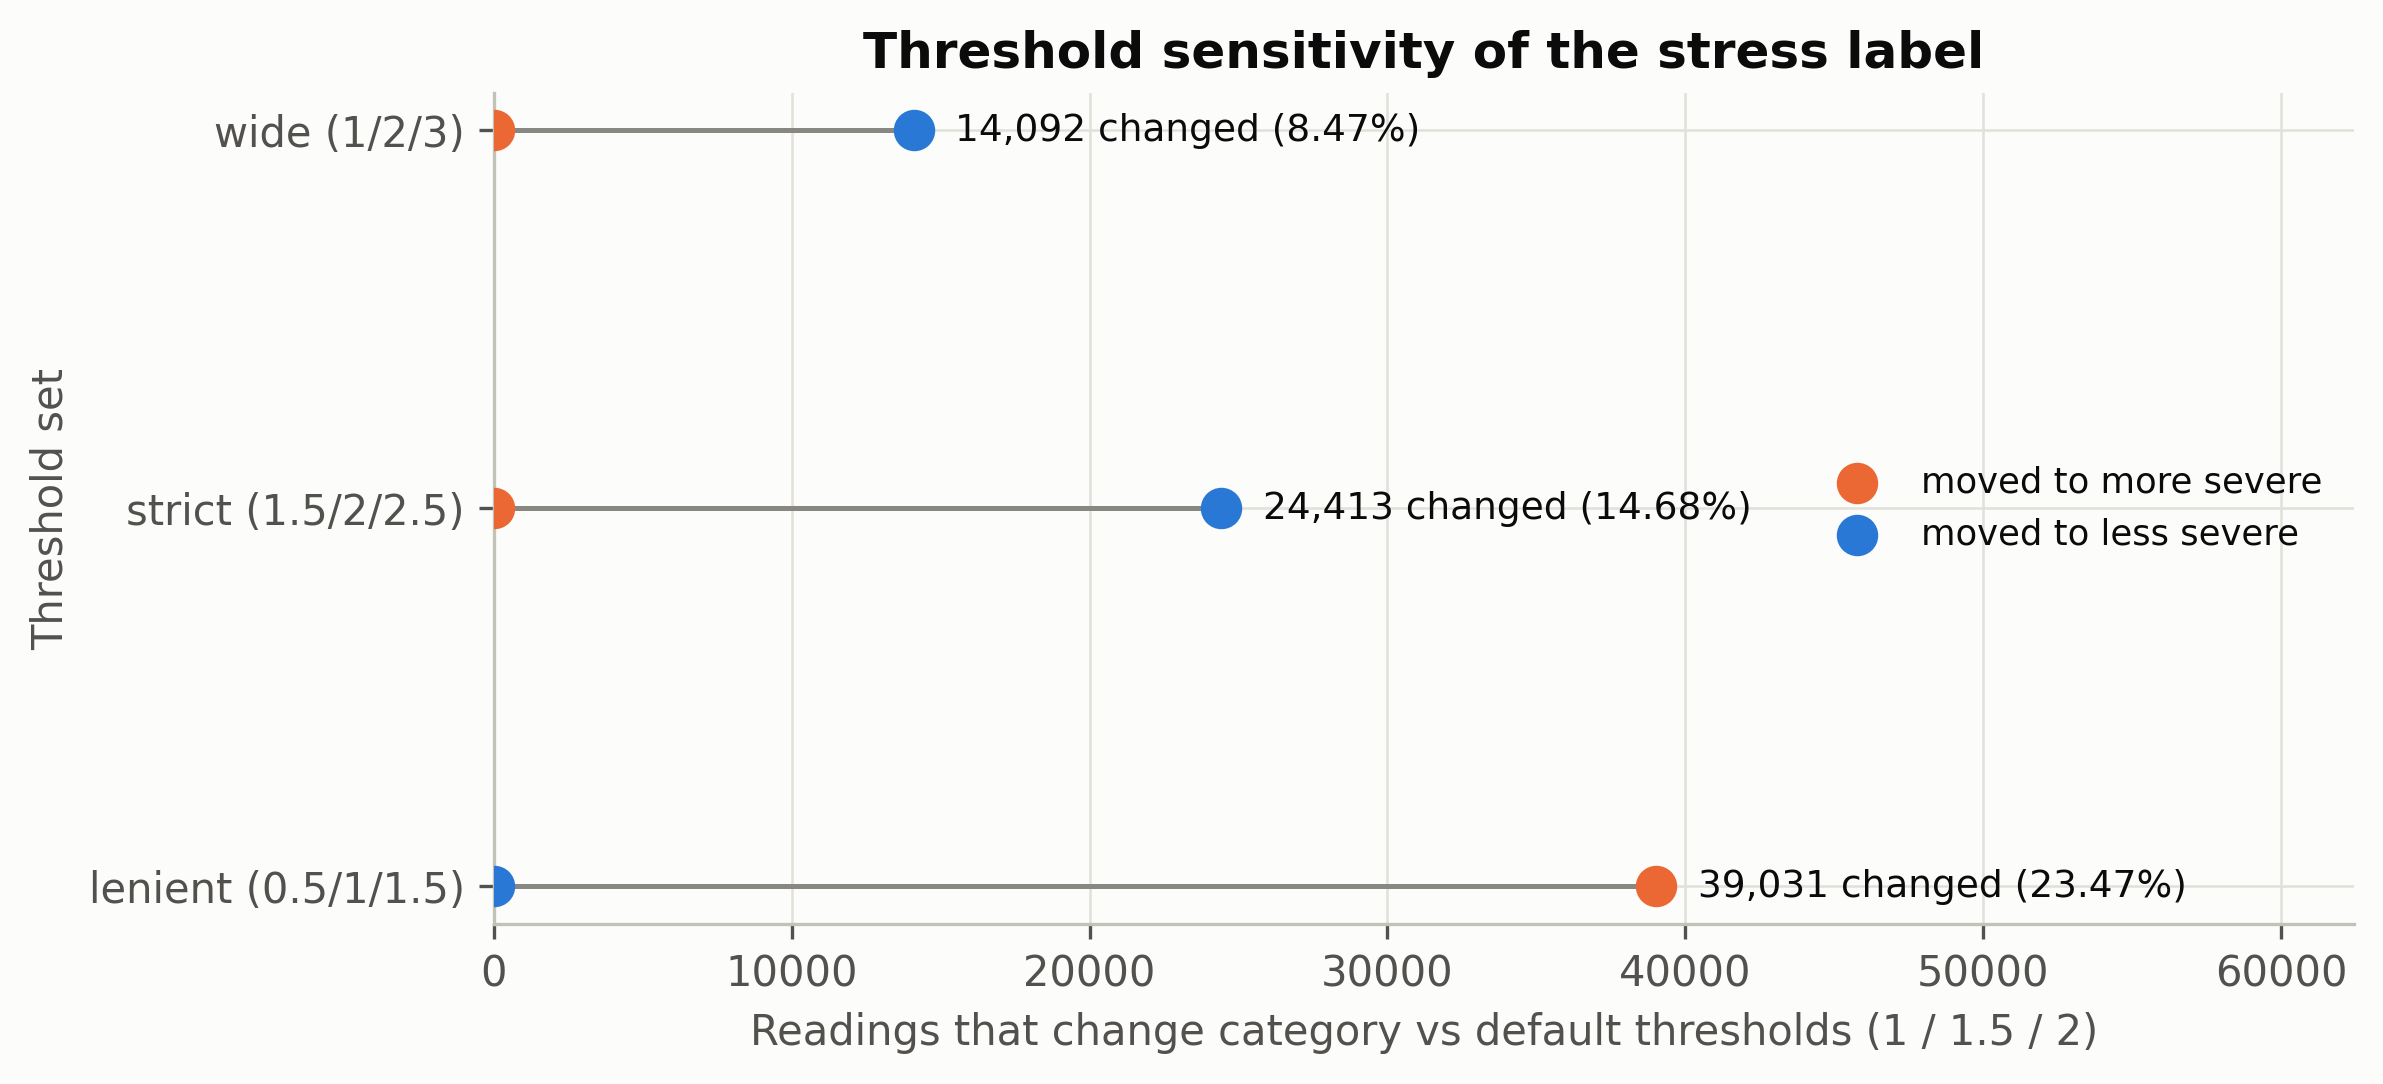

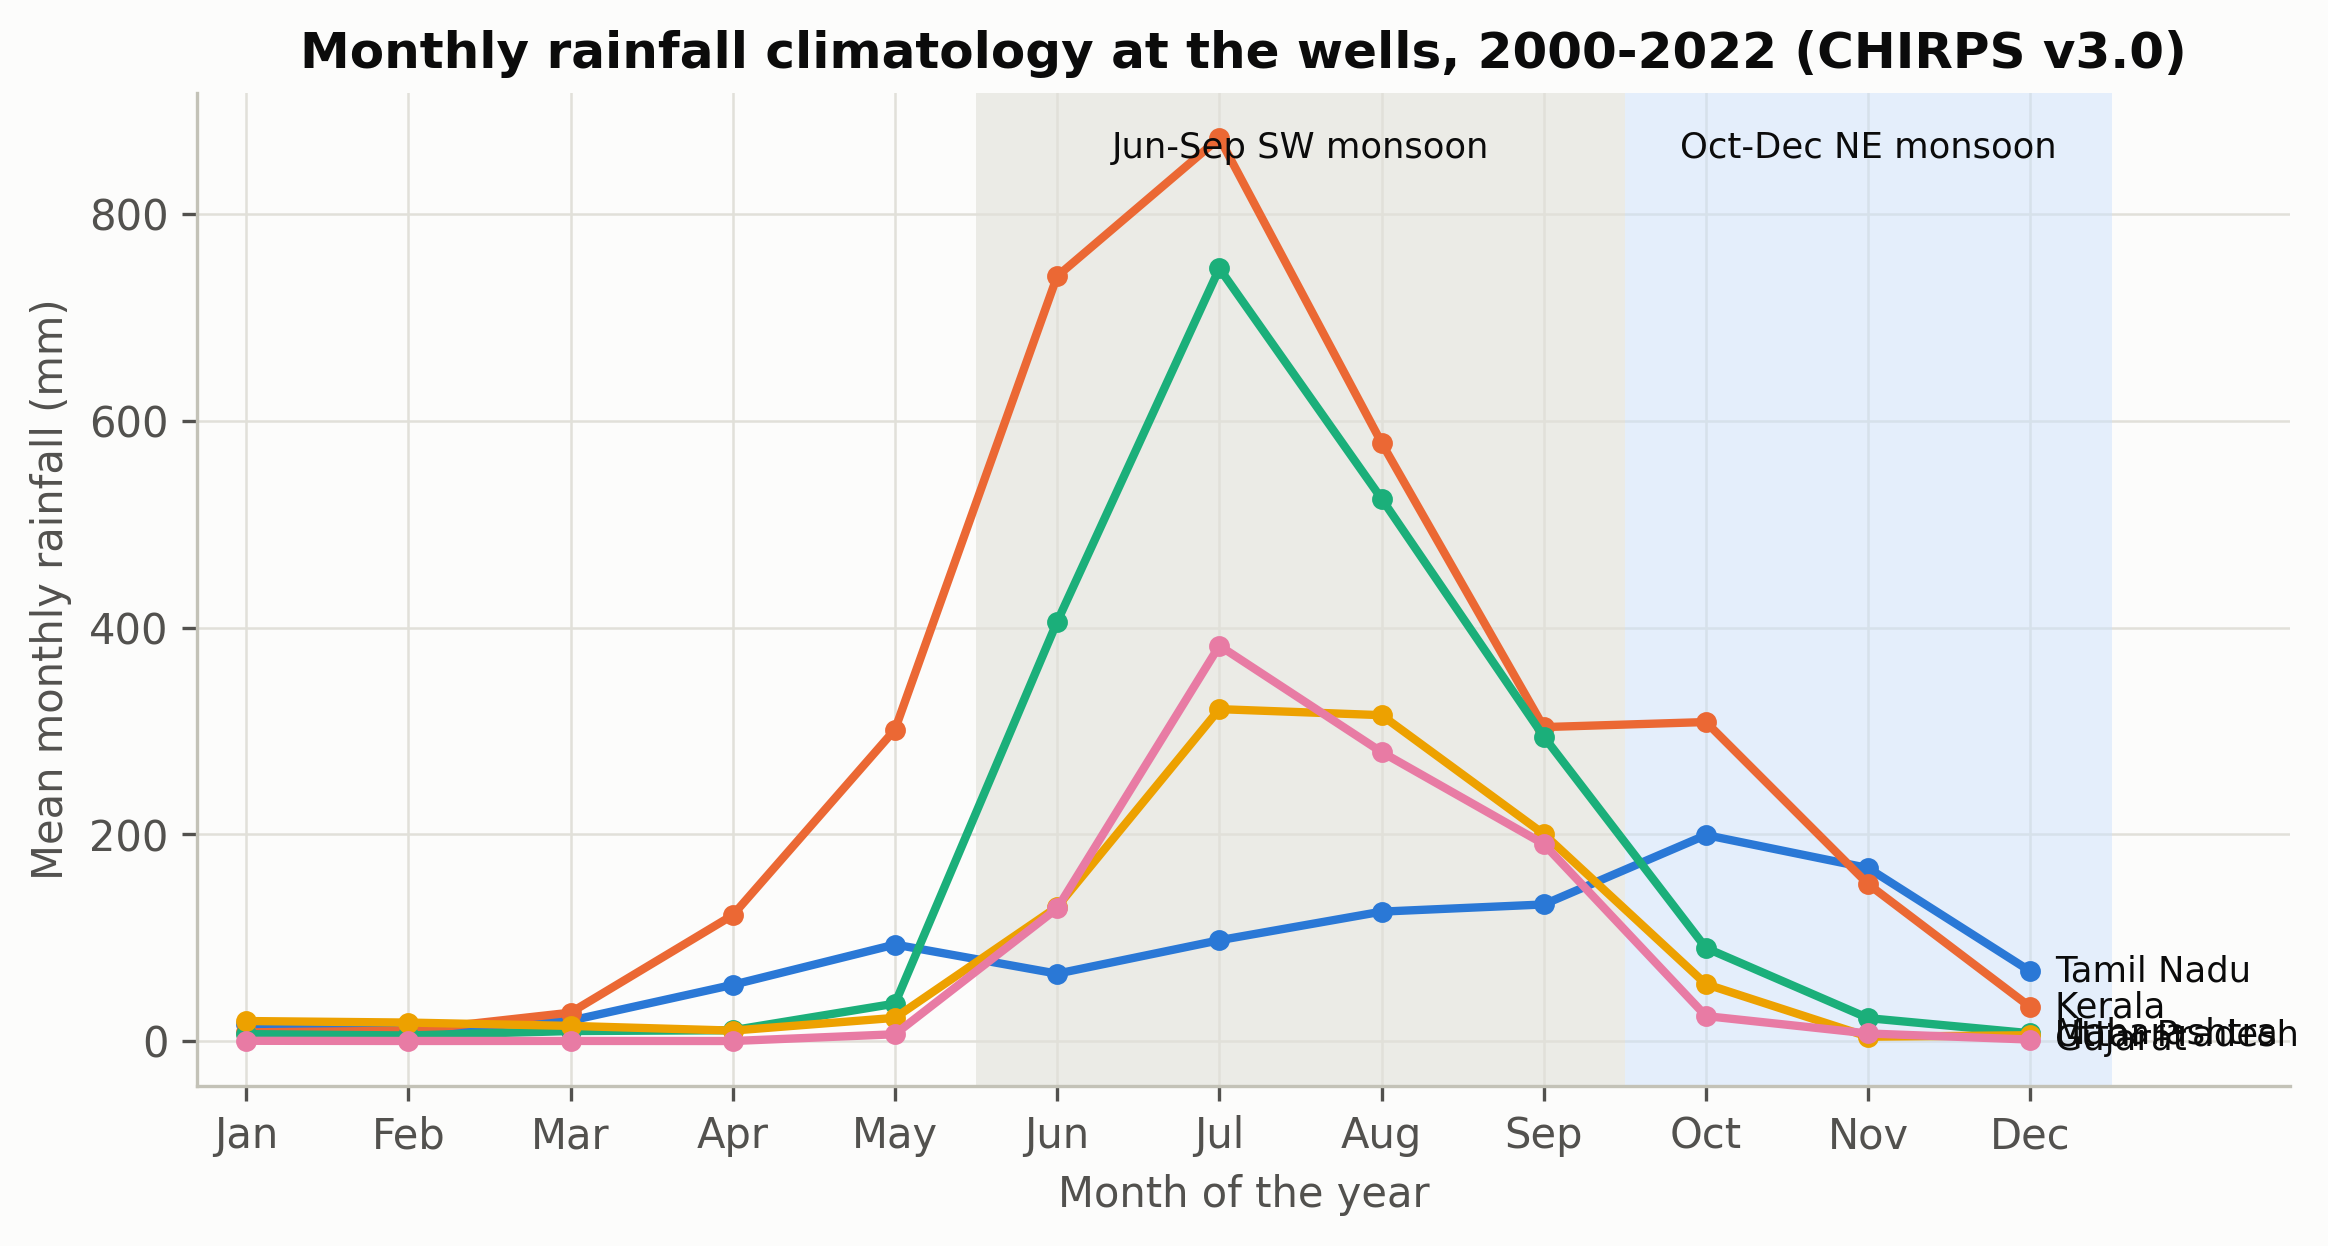

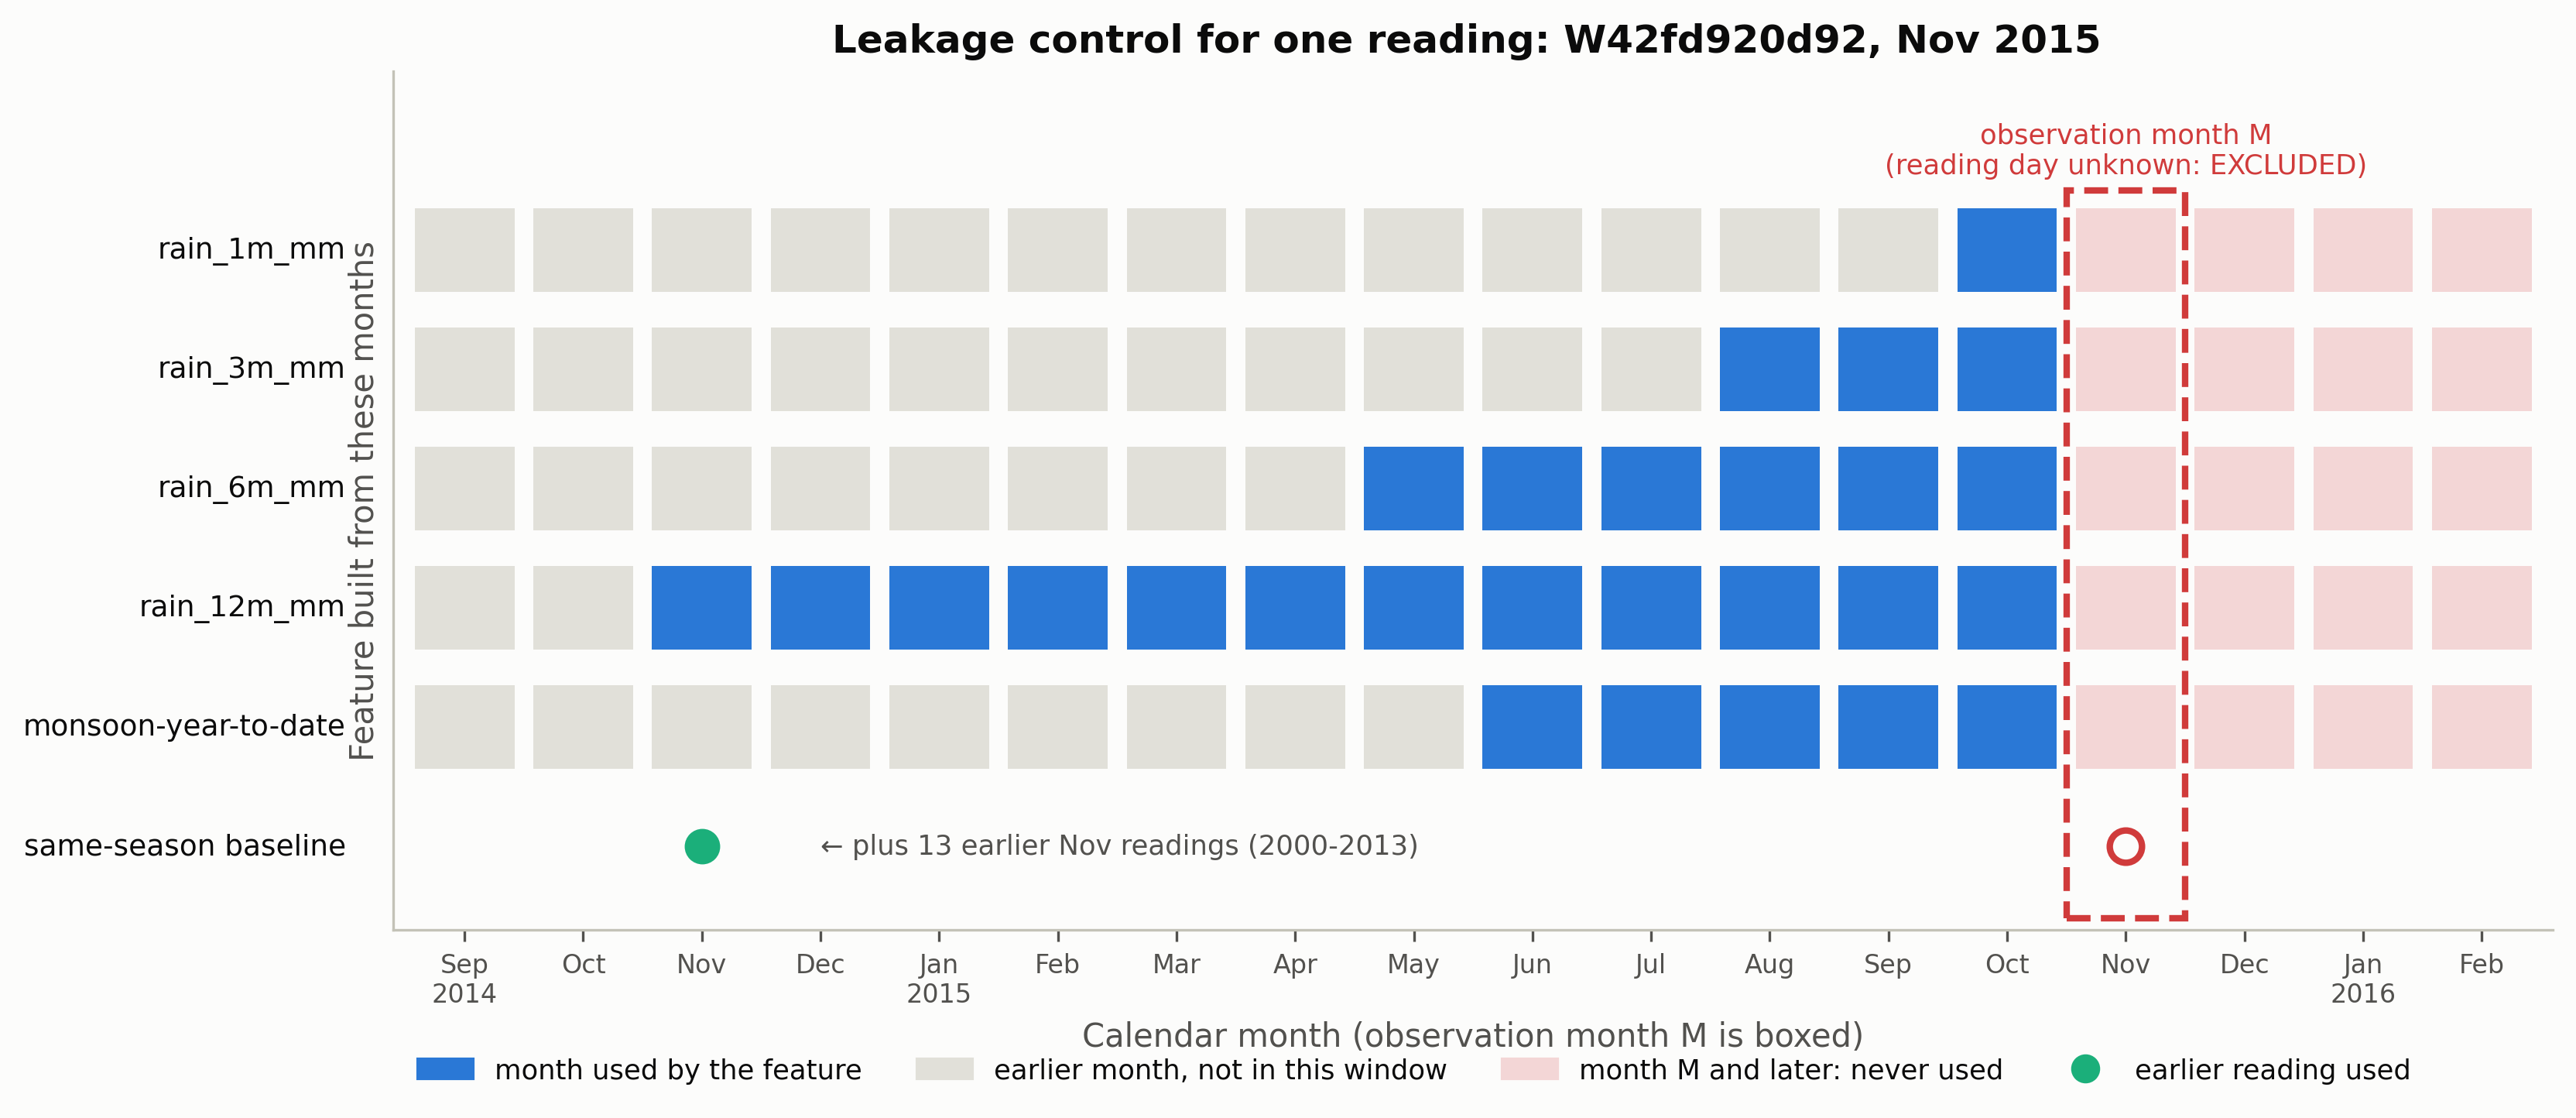

Readings without a baseline (fewer than 5 earlier same-season readings): 52952 (20.9%)


In [8]:
pic(FIGS / "fig01_missingness_heatmap.png", 1000)     # heatmap: share of wells with a reading by season and year
pic(FIGS / "fig02_cleaning_stages.png", 900)          # connected dots: wells and rows at each cleaning stage
pic(FIGS / "fig08_stress_counts_by_method.png", 900)  # heatmap: stress categories under three baselines
pic(FIGS / "fig07_anomaly_distribution.png", 800)     # step lines: anomaly distributions (log scale)
pic(FIGS / "fig09_excess_high_stress.png", 900)       # dots and lines: why High Stress exceeds 2.28%
pic(FIGS / "fig10_threshold_sensitivity.png", 900)    # dumbbell: readings that change category under other thresholds
pic(FIGS / "fig12a_rainfall_climatology.png", 900)    # lines on shaded monsoon bands: CHIRPS rainfall by month
pic(FIGS / "fig13_leakage_timeline.png", 900)         # timeline matrix: months each rainfall feature uses
print("Readings without a baseline (fewer than 5 earlier same-season readings): %d (%.1f%%)" % ((m.stress_category.astype(str) == "Insufficient history").sum(), 100 * (m.stress_category.astype(str) == "Insufficient history").mean()))

**Error metrics before vs after cleaning.** Preprocessing makes no predictions, so we score the *data*: a fixed past-only rule (predict each 2018-2022 reading with the same season one year earlier) is applied to the **raw** values and to the **cleaned** values of the same 2,759 wells. If cleaning improves the data, the same rule scores better. The authors' cleaning blanked 1,217 implausible raw readings and changed none; our own pipeline only adds flags.

,metric,before (raw),after (cleaned),change_%,verdict
0,RMSE (m),2.684,2.554,-4.821,better
1,MSE (m²),7.203,6.525,-9.410,better
2,MAE (m),1.542,1.491,-3.322,better
3,MAPE (%),37.779,36.843,-2.478,better
4,R²,0.689,0.712,3.307,better
5,NRMSE (fraction of range),0.040,0.038,-4.821,better
6,MedAE (m),0.850,0.830,-2.353,better
7,Bias (m),0.210,0.209,-0.530,better


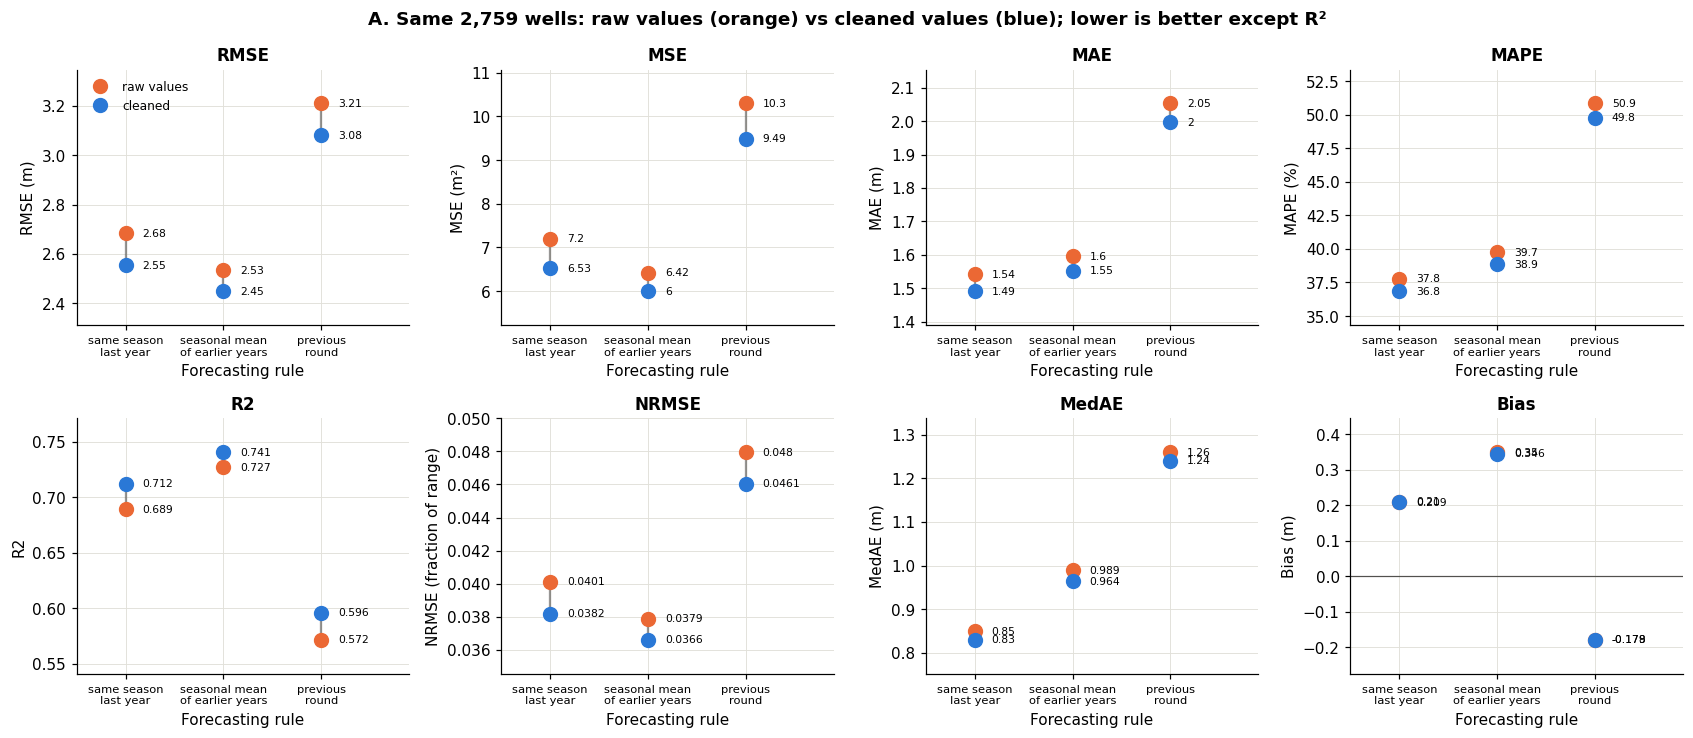

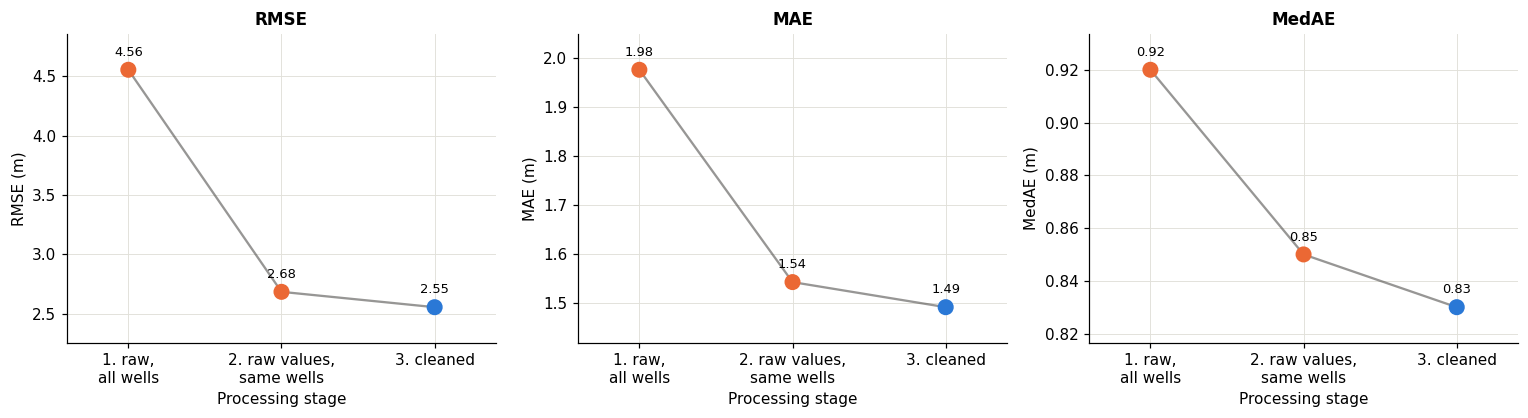

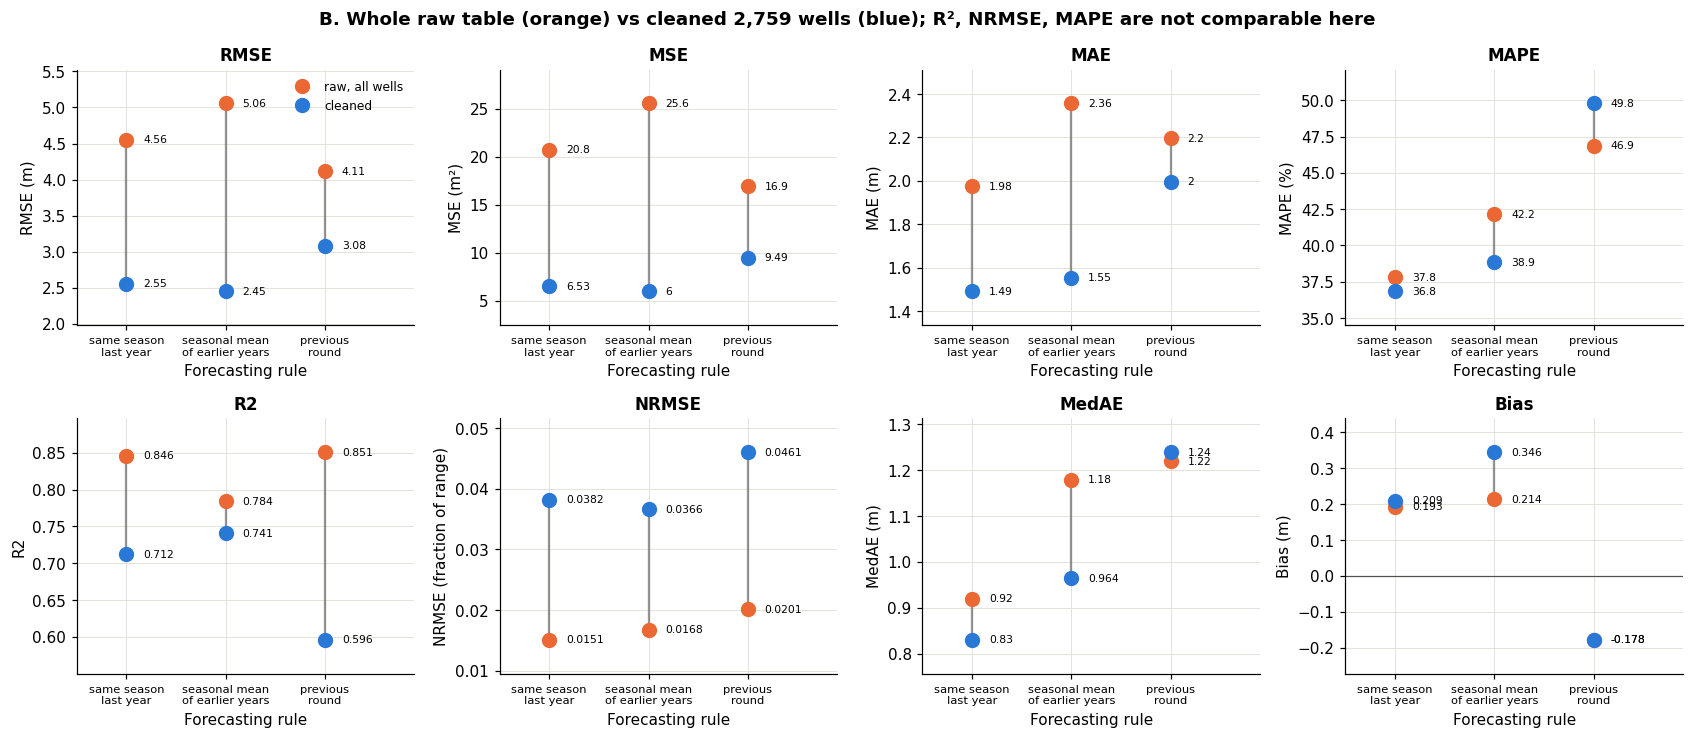

PASS  all eight preprocessing metrics improve after cleaning


In [9]:
cmp_ = pd.read_csv(ROOT / "reports" / "tables" / "error_metrics_comparison.csv")
cmp_ = cmp_[cmp_.comparison.str.startswith("A") & (cmp_.rule == "same season last year")].copy()
cmp_["metric"] = cmp_.metric.str.replace("�", "²").str.replace("R2", "R²")
cmp_["change_%"] = 100 * (cmp_.after - cmp_.before) / cmp_.before.abs()
display(cmp_[["metric", "before", "after", "change_%", "verdict"]].round(3).rename(columns={"before": "before (raw)", "after": "after (cleaned)"}))
A_ = ROOT / "notebooks" / "assets"
pic(A_ / "prep_error_same_wells_raw_vs_cleaned.png", 1000)   # dot plots: all eight metrics, raw (orange) vs cleaned (blue), same wells
pic(A_ / "prep_error_stages.png", 900)                       # lines: RMSE, MAE, MedAE through the processing stages
pic(A_ / "prep_error_all_wells_dumbbell.png", 1000)          # dumbbells: whole raw table vs cleaned table
check("all eight preprocessing metrics improve after cleaning", (cmp_.verdict == "better").all() and len(cmp_) == 8)

## 5 · TGT-M inputs, label and training (slide: Classification: the proposed model)
**Task (hidden-reading estimate):** predict the *anomaly* z of a reading from the past; depth = baseline + z x SD; stress class from z at 1 / 1.5 / 2 (Watch / Moderate / High). The baseline uses **only earlier readings of the same season** (at least 5).

**Input:** 12 past rounds + the current round as a 13-step sequence (reading, mask, season, rainfall; the current reading is always hidden) plus a static vector (well metadata, baseline, lags, rainfall at M-1). No latitude, longitude, state or year is used.

Well Cherfully (Thane), round May-06. Earlier May readings used: [1.25, 1.54, 1.7, 1.65, 2.28]
computed here : baseline mean 1.684  SD 0.376  z 2.037  -> High Stress
pipeline value: baseline mean 1.684  SD 0.376  z 2.037  -> High Stress
PASS  z computed by hand equals the pipeline z


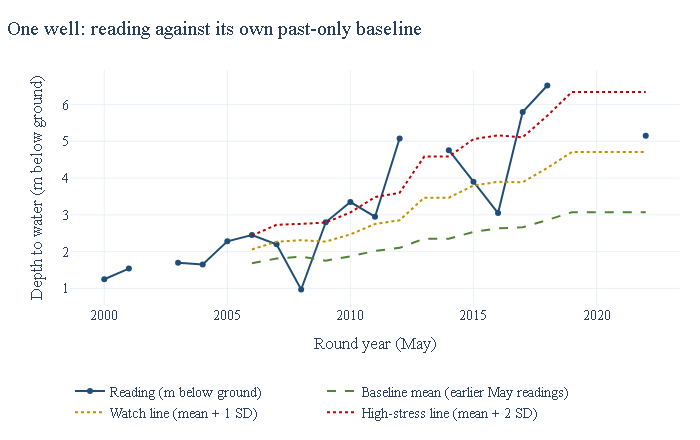

Sequence tensor for that round (last row = the round to predict, reading hidden):


,reading (rel.),mask,Jan,May,Aug,Nov,valid,log rain 1m,log rain 3m,spare
t-12,0.04,1.0,0.0,1.0,0.0,0.0,1.0,0.00,0.24,0.0
t-11,-3.23,1.0,0.0,0.0,1.0,0.0,1.0,6.93,7.31,0.0
t-10,1.16,1.0,0.0,0.0,0.0,1.0,1.0,3.94,6.62,0.0
t-9,-0.76,1.0,1.0,0.0,0.0,0.0,1.0,0.53,3.98,0.0
t-8,-0.09,1.0,0.0,1.0,0.0,0.0,1.0,0.00,0.18,0.0
t-7,0.00,0.0,0.0,0.0,1.0,0.0,1.0,7.20,7.45,0.0
t-6,0.00,0.0,0.0,0.0,0.0,1.0,1.0,3.74,7.34,0.0
t-5,-1.23,1.0,1.0,0.0,0.0,0.0,1.0,0.30,3.98,0.0
t-4,1.58,1.0,0.0,1.0,0.0,0.0,1.0,0.00,0.18,0.0
t-3,-2.62,1.0,0.0,0.0,1.0,0.0,1.0,7.13,7.54,0.0


PASS  no location or year columns among the model inputs


In [10]:
w = m[(m.well_id == "Wa62f7df166") & (m.season == "pre_monsoon")].sort_values("date").reset_index(drop=True)
i = w.index[w.period_label == "May-06"][0]
earlier = w.loc[:i - 1, "gwl_m_bgl"].dropna()
mean, sd = earlier.mean(), earlier.std(ddof=1)
z = (w.gwl_m_bgl[i] - mean) / max(sd, 0.10)
print(f"Well {w.station_name.iloc[0]} ({w.district.iloc[0]}), round May-06. Earlier May readings used: {earlier.round(2).tolist()}")
print(f"computed here : baseline mean {mean:.3f}  SD {sd:.3f}  z {z:.3f}  -> {'High Stress' if z >= 2 else 'Moderate Stress' if z >= 1.5 else 'Watch' if z >= 1 else 'Normal'}")
print(f"pipeline value: baseline mean {w.baseline_mean_m[i]:.3f}  SD {w.baseline_std_m[i]:.3f}  z {w.anomaly_z[i]:.3f}  -> {w.stress_category[i]}")
check("z computed by hand equals the pipeline z", abs(z - w.anomaly_z[i]) < 1e-6)
ww = w.dropna(subset=["baseline_mean_m"])
fig = go.Figure()
fig.add_scatter(x=w.year, y=w.gwl_m_bgl, mode="lines+markers", name="Reading (m below ground)", line=dict(color=PAL["A"]))
fig.add_scatter(x=ww.year, y=ww.baseline_mean_m, mode="lines", name="Baseline mean (earlier May readings)", line=dict(color=PAL["G"], dash="dash"))
fig.add_scatter(x=ww.year, y=ww.baseline_mean_m + ww.baseline_std_m, mode="lines", name="Watch line (mean + 1 SD)", line=dict(color="#BF9000", dash="dot"))
fig.add_scatter(x=ww.year, y=ww.baseline_mean_m + 2 * ww.baseline_std_m, mode="lines", name="High-stress line (mean + 2 SD)", line=dict(color="#C00000", dash="dot"))
show(fig, "One well: reading against its own past-only baseline", "Round year (May)", "Depth to water (m below ground)")
k = int(np.flatnonzero((meta.well_id == "Wa62f7df166") & (meta.period_label == "May-06"))[0])
ch = ["reading (rel.)", "mask", "Jan", "May", "Aug", "Nov", "valid", "log rain 1m", "log rain 3m", "spare"]
print("Sequence tensor for that round (last row = the round to predict, reading hidden):")
display(pd.DataFrame(b["seq"][k], columns=ch, index=[f"t-{12 - j}" if j < 12 else "t (hidden)" for j in range(13)]).round(2))
banned = {"lat", "lon", "state", "district", "year"}
check("no location or year columns among the model inputs", not (banned & set(b["names"])))

**The TGT-M source code** (`modeling/nets.py`): the GRU-D encoder, the gated residual network, the variable-selection network and the full model.

In [11]:
for obj in (N.GRUD, N.GRN, N.VSN2):
    print(inspect.getsource(obj)); print("-" * 90)
print(inspect.getsource(N.TGTM))
print(inspect.getsource(N.TGTM2))

class GRUD(nn.Module):
    """GRU-D encoder. Channel 0 = relative reading, 1 = mask; other channels are always observed."""

    def __init__(self, n_ch, d):
        super().__init__()
        self.d = d
        self.gx = nn.Linear(1, 1)
        self.gh = nn.Linear(1, d)
        self.cell = nn.GRUCell(n_ch, d)

    def forward(self, seq):
        B, T, _ = seq.shape
        h = seq.new_zeros(B, self.d)
        x_last = seq.new_zeros(B, 1)
        delta = seq.new_zeros(B, 1)
        prev_m = seq.new_ones(B, 1)
        out = []
        for t in range(T):
            x, m = seq[:, t, 0:1], seq[:, t, 1:2]
            delta = torch.where(prev_m > 0, torch.ones_like(delta), delta + 1) if t else delta
            dn = delta / 12.0
            gamma_x = torch.exp(-F.relu(self.gx(dn)))
            x_hat = m * x + (1 - m) * gamma_x * x_last         # decay toward the well's baseline (0)
            gamma_h = torch.exp(-F.relu(self.gh(dn)))
            h = self.cell(torch.cat([x_hat, m, seq[:, t,

**Live mini training** with the study's own training function (`lib.fit_deep`: AdamW, Huber loss on the point + pinball loss on the quantiles, early stopping) on 6,000 random training rows. It is only to show the loop learns; the published numbers come from the full run (Section 6).

trained on 6,000 rows in 23s | best validation |z| MAE 0.835 | predicting z = 0 (the baseline) gives 0.965


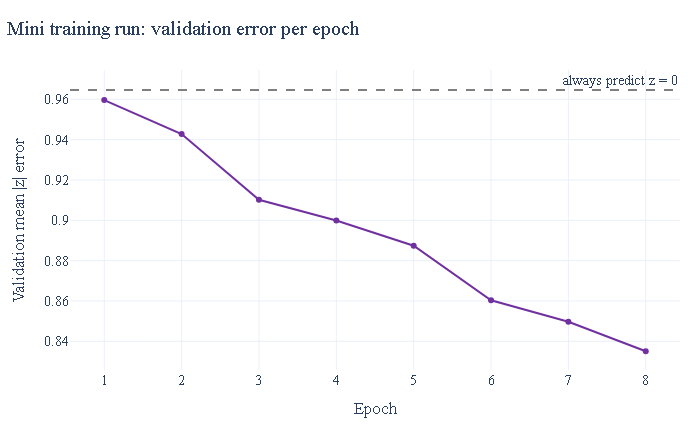

PASS  mini training beats the seasonal baseline on validation rows


In [12]:
import warnings, re, time; warnings.filterwarnings("ignore")
rng = np.random.default_rng(0)
tr_s = np.zeros(len(meta), bool); tr_s[rng.choice(np.flatnonzero(tr), 6000, replace=False)] = True
va_s = np.zeros(len(meta), bool); va_s[rng.choice(np.flatnonzero(va), 2000, replace=False)] = True
y = meta["anomaly_z_capped"].to_numpy()
buf = io.StringIO(); t0 = time.time()
with contextlib.redirect_stdout(buf):
    net2, best, ep = Lb.fit_deep("TGT-M", Bq, y, tr_s, va_s, cfg, 0, epochs=8, patience=4, verbose=True)
curve = [float(v) for v in re.findall(r"val \|z\| MAE ([0-9.]+)", buf.getvalue())]
zero = float(np.abs(y[va_s]).mean())
print(f"trained on 6,000 rows in {time.time() - t0:.0f}s | best validation |z| MAE {best:.3f} | predicting z = 0 (the baseline) gives {zero:.3f}")
fig = go.Figure()
fig.add_scatter(x=list(range(1, len(curve) + 1)), y=curve, mode="lines+markers", name="TGT-M validation error", line=dict(color=PAL["T"]))
fig.add_hline(y=zero, line_dash="dash", line_color=PAL["grey"], annotation_text="always predict z = 0")
show(fig, "Mini training run: validation error per epoch", "Epoch", "Validation mean |z| error")
check("mini training beats the seasonal baseline on validation rows", best < zero)

## 6 · Results of the proposed model (slides: Results with TGT-M, Regression metrics, Classification metrics)
Test split 2018 to 2022 (**40,630 rows**), three random seeds, from the saved study outputs (`results/`). Model A = without rainfall, Model B = with rainfall.

,Model,Depth MAE (m),Depth RMSE (m),Anomaly R²,Accuracy,Macro-F1,AUC (stressed vs not)
0,TGT-M (A: no rainfall),1.338,2.117,0.111,0.706,0.349,0.759
1,TGT-M (B: with rainfall),1.129,1.811,0.279,0.770,0.382,0.795


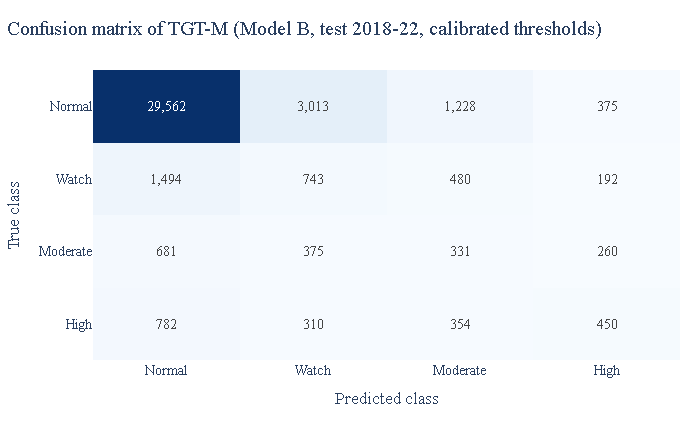

PASS  confusion matrix covers all 40,630 test rows


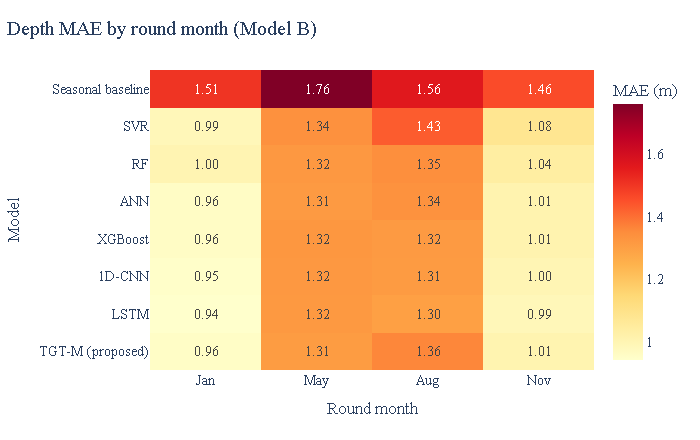

In [13]:
rd = pd.read_csv(T / "model_metrics_regression_depth.csv"); ra = pd.read_csv(T / "model_metrics_regression_anomaly.csv")
cl = pd.read_csv(T / "model_metrics_classification.csv"); cl = cl[cl.thresholds == "validation-calibrated"]
rows = []
for v, nm in (("A", "TGT-M (A: no rainfall)"), ("B", "TGT-M (B: with rainfall)")):
    d_, a_, c_ = rd[(rd.model == "TGT-M") & (rd.variant == v)].iloc[0], ra[(ra.model == "TGT-M") & (ra.variant == v)].iloc[0], cl[(cl.model == "TGT-M") & (cl.variant == v)].iloc[0]
    rows.append([nm, d_.MAE, d_.RMSE, a_.R2, c_.accuracy, c_.F1_macro, c_.AUC_ROC_stressed])
display(pd.DataFrame(rows, columns=["Model", "Depth MAE (m)", "Depth RMSE (m)", "Anomaly R²", "Accuracy", "Macro-F1", "AUC (stressed vs not)"]).round(3))
cm = np.array(json.load(open(T / "confusion_matrices_calibrated.json"))["TGT-M|B"]); D4 = ["Normal", "Watch", "Moderate", "High"]
fig = go.Figure(go.Heatmap(z=cm, x=D4, y=D4, colorscale="Blues", text=[[f"{v:,}" for v in r] for r in cm], texttemplate="%{text}", showscale=False))
show(fig, "Confusion matrix of TGT-M (Model B, test 2018-22, calibrated thresholds)", "Predicted class", "True class", h=430, yaxis_autorange="reversed")
check("confusion matrix covers all 40,630 test rows", int(cm.sum()) == 40630)
sea = pd.read_csv(T / "chrono_by_season.csv"); nmap = {"post_monsoon_rabi": "Jan", "pre_monsoon": "May", "monsoon": "Aug", "post_monsoon_kharif": "Nov"}
mods = ["Seasonal baseline", "SVR", "RF", "ANN", "XGBoost", "CNN1D", "LSTM", "TGT-M"]
z_ = [[float(sea[(sea.model == mo) & (sea.variant == "B") & (sea.season == k)].depth_MAE.iloc[0]) for k in nmap] for mo in mods]
fig = go.Figure(go.Heatmap(z=z_, x=list(nmap.values()), y=[lab(mo) for mo in mods], colorscale="YlOrRd", text=[[f"{v:.2f}" for v in r] for r in z_], texttemplate="%{text}", colorbar=dict(title="MAE (m)")))
show(fig, "Depth MAE by round month (Model B)", "Round month", "Model", h=440, yaxis_autorange="reversed")

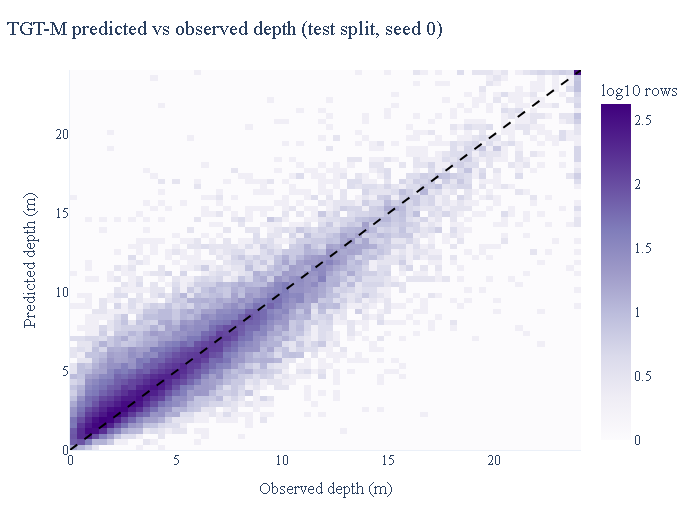

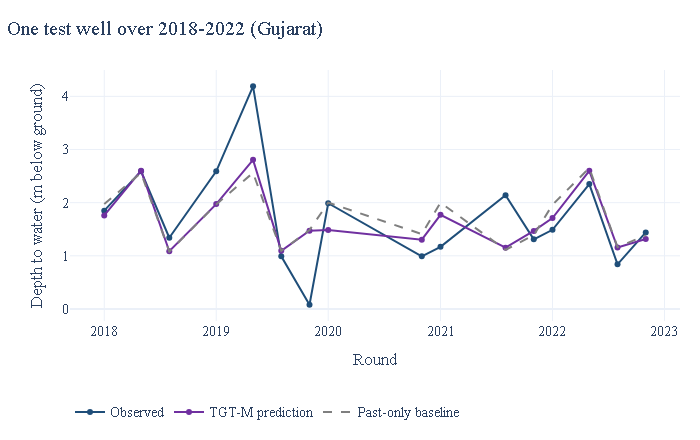

In [14]:
tp = pd.read_csv(ROOT / "results" / "powerbi" / "test_predictions.csv")
s_ = tp.sample(4000, random_state=0); mx = float(np.nanpercentile(tp.gwl_m_bgl, 99))
Hd, xe, ye = np.histogram2d(tp.gwl_m_bgl.clip(0, mx), tp["TGT-M_B_depth_pred"].clip(0, mx), bins=70, range=[[0, mx], [0, mx]])
fig = go.Figure(go.Heatmap(z=np.log10(Hd.T + 1), x=(xe[:-1] + xe[1:]) / 2, y=(ye[:-1] + ye[1:]) / 2, colorscale="Purples", colorbar=dict(title="log10 rows")))
fig.add_scatter(x=[0, mx], y=[0, mx], mode="lines", line=dict(color="black", dash="dash"), name="perfect prediction")
show(fig, "TGT-M predicted vs observed depth (test split, seed 0)", "Observed depth (m)", "Predicted depth (m)", xaxis_range=[0, mx], yaxis_range=[0, mx], h=520)
wid = tp.groupby("well_id").size().idxmax(); x = tp[tp.well_id == wid].copy()
x["t"] = pd.to_datetime("20" + x.period_label.str[-2:] + "-" + x.period_label.str[:3], format="%Y-%b")
x = x.sort_values("t")
fig = go.Figure()
fig.add_scatter(x=x.t, y=x.gwl_m_bgl, mode="lines+markers", name="Observed", line=dict(color=PAL["A"]))
fig.add_scatter(x=x.t, y=x["TGT-M_B_depth_pred"], mode="lines+markers", name="TGT-M prediction", line=dict(color=PAL["T"]))
fig.add_scatter(x=x.t, y=x.baseline_mean_m, mode="lines", name="Past-only baseline", line=dict(color=PAL["grey"], dash="dash"))
show(fig, f"One test well over 2018-2022 ({x.state.iloc[0]})", "Round", "Depth to water (m below ground)")

**Interpretability.** The variable-selection network gives a weight to every input; attention shows which of the 13 steps the current round looks at. Both are diagnostics, not accuracy results: the rainfall weight is close to the uniform share, so we do **not** claim rainfall dominance from it.

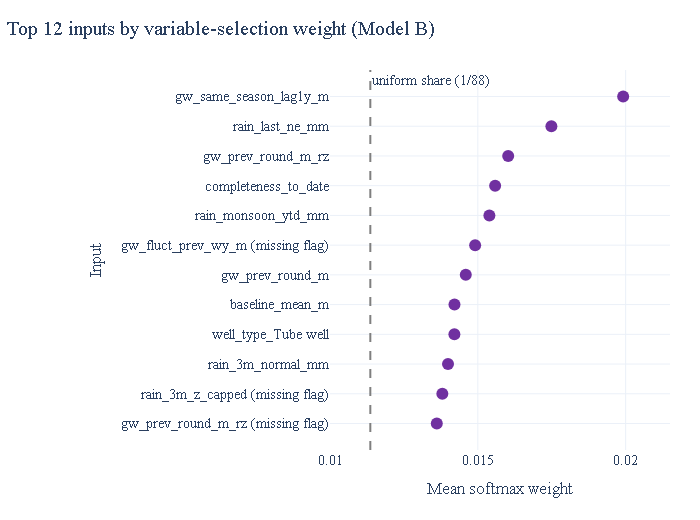

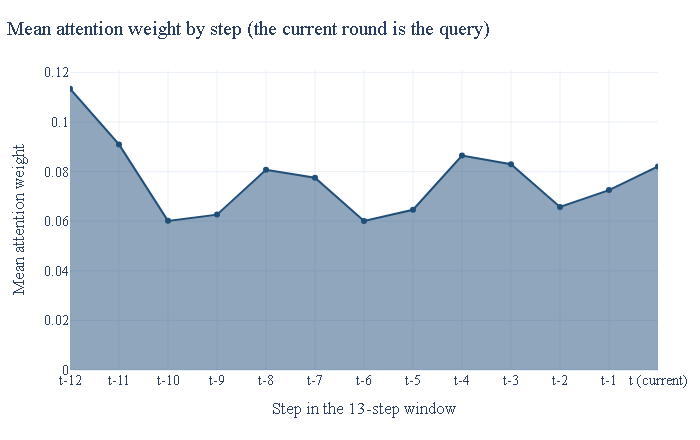

VSN weight on the 24 rainfall inputs: 26.6% (a uniform split would give 27.3%)  |  80% interval coverage on test: 79.2%, mean width 2.32 z-units


In [15]:
S = json.load(open(ROOT / "results" / "summary.json"))["tgtm"]["B"]
names = list(Bq.names) + [n + " (missing flag)" for n, f in zip(Bq.names, Bq.sc.flag) if f]
vw = pd.Series(S["vsn_w_mean"], index=names).sort_values(ascending=False).head(12)
fig = go.Figure(go.Scatter(x=list(vw.values), y=list(vw.index), mode="markers", marker=dict(size=12, color=PAL["T"]), name="mean weight"))
fig.add_vline(x=1 / len(S["vsn_w_mean"]), line_dash="dash", line_color=PAL["grey"], annotation_text="uniform share (1/88)")
show(fig, "Top 12 inputs by variable-selection weight (Model B)", "Mean softmax weight", "Input", h=520, yaxis_autorange="reversed", margin=dict(l=330, r=30, t=70, b=70), xaxis_range=[0.010, 0.0215])
steps = ["t-12", "t-11", "t-10", "t-9", "t-8", "t-7", "t-6", "t-5", "t-4", "t-3", "t-2", "t-1", "t (current)"]
fig = go.Figure(go.Scatter(x=steps, y=S["attn_mean_by_step"], mode="lines+markers", fill="tozeroy", line=dict(color=PAL["A"])))
show(fig, "Mean attention weight by step (the current round is the query)", "Step in the 13-step window", "Mean attention weight")
print(f"VSN weight on the 24 rainfall inputs: {S['vsn_rain_weight']:.1%} (a uniform split would give {24 / 88:.1%})  |  80% interval coverage on test: {S['PI80_coverage']:.1%}, mean width {S['PI80_width']:.2f} z-units")

**Full metric tables** (the formulas of the report, Section 3.5, computed from the saved test predictions of all three seeds, Model B): regression on depth and classification of the four stress classes. Log loss is not computed because the models output numbers, not class probabilities.

In [16]:
order = ["Prev. round", "Same season LY", "Seasonal baseline", "SVR", "RF", "ANN", "XGBoost", "CNN1D", "LSTM", "TGT-M"]
pick = lambda df, v: pd.concat([df[(df.model == k) & (df.variant == ("A/B" if k in order[:3] else v))] for k in order])
reg = pick(rd, "B")[["model", "RMSE", "MSE", "MAE", "MAPE_pct", "R2", "NRMSE_range", "MedAE", "Bias"]].copy(); reg["model"] = reg.model.map(lab)
display(reg.rename(columns={"model": "Model", "MAPE_pct": "MAPE (%)", "NRMSE_range": "NRMSE"}).round(4).reset_index(drop=True))
cls = pick(cl, "B")[["model", "accuracy", "precision_macro", "recall_macro", "F1_macro", "specificity_macro", "AUC_ROC_stressed", "MCC", "kappa", "balanced_accuracy"]].copy(); cls["model"] = cls.model.map(lab)
display(cls.rename(columns={"model": "Model", "precision_macro": "precision", "recall_macro": "recall", "F1_macro": "F1", "specificity_macro": "specificity", "AUC_ROC_stressed": "AUC-ROC"}).round(3).reset_index(drop=True))
# recompute TGT-M metrics from the saved seed-0 predictions with the plain formulas
e = tp["TGT-M_B_depth_pred"] - tp.gwl_m_bgl; y_ = tp.gwl_m_bgl
mine = {"RMSE": float(np.sqrt((e ** 2).mean())), "MAE": float(e.abs().mean()), "R2": float(1 - (e ** 2).sum() / ((y_ - y_.mean()) ** 2).sum()), "MedAE": float(e.abs().median()), "Bias": float(e.mean())}
ref = rd[(rd.model == "TGT-M") & (rd.variant == "B")].iloc[0]
display(pd.DataFrame({"formula on seed-0 predictions": mine, "table (mean of 3 seeds)": {k: float(ref[k]) for k in mine}, "seed spread (SD)": {k: float(ref[k + "_sd"]) for k in mine}}).round(3))
check("TGT-M metrics recomputed from the seed-0 predictions lie within 3 seed-SDs of the table's 3-seed mean", all(abs(mine[k] - float(ref[k])) <= 3 * float(ref[k + "_sd"]) + 0.005 for k in mine))

,Model,RMSE,MSE,MAE,MAPE (%),R2,NRMSE,MedAE,Bias
0,Previous round,3.1140,9.6967,2.0502,54.0512,0.5812,0.0465,1.3000,0.0492
1,Same season last year,2.5557,6.5316,1.5070,37.1746,0.7179,0.0382,0.8500,0.2722
2,Seasonal baseline,2.4453,5.9794,1.5484,38.7058,0.7418,0.0366,0.9610,0.3695
3,SVR,1.9013,3.6150,1.1799,29.8328,0.8439,0.0284,0.7324,0.2008
4,RF,1.8488,3.4180,1.1501,28.4132,0.8524,0.0276,0.7144,0.1457
5,ANN,1.8177,3.3044,1.1249,27.5968,0.8573,0.0272,0.6897,0.1085
6,XGBoost,1.8274,3.3393,1.1211,27.2719,0.8558,0.0273,0.6787,0.1116
7,1D-CNN,1.8074,3.2672,1.1132,27.2389,0.8589,0.0270,0.6735,0.1223
8,LSTM,1.7843,3.1838,1.1038,27.1062,0.8625,0.0267,0.6748,0.1263
9,TGT-M (proposed),1.8111,3.2801,1.1287,28.3477,0.8583,0.0271,0.6942,0.1939


,Model,accuracy,precision,recall,F1,specificity,AUC-ROC,MCC,kappa,balanced_accuracy
0,Previous round,0.681,0.320,0.362,0.325,0.809,0.680,0.155,0.147,0.362
1,Same season last year,0.759,0.342,0.344,0.343,0.807,0.678,0.174,0.174,0.344
2,Seasonal baseline,0.841,0.210,0.250,0.228,0.750,0.500,0.000,0.000,0.250
3,SVR,0.779,0.404,0.369,0.374,0.831,0.781,0.243,0.242,0.369
4,RF,0.776,0.384,0.368,0.370,0.833,0.781,0.243,0.241,0.368
5,ANN,0.777,0.411,0.379,0.381,0.839,0.793,0.260,0.258,0.379
6,XGBoost,0.774,0.388,0.366,0.368,0.834,0.788,0.241,0.240,0.366
7,1D-CNN,0.782,0.408,0.375,0.379,0.839,0.797,0.261,0.259,0.375
8,LSTM,0.787,0.414,0.383,0.388,0.840,0.801,0.267,0.266,0.383
9,TGT-M (proposed),0.770,0.391,0.384,0.382,0.840,0.795,0.256,0.254,0.384


,formula on seed-0 predictions,table (mean of 3 seeds),seed spread (SD)
RMSE,1.813,1.811,0.010
MAE,1.137,1.129,0.008
R2,0.858,0.858,0.002
MedAE,0.699,0.694,0.004
Bias,0.239,0.194,0.063


PASS  TGT-M metrics recomputed from the seed-0 predictions lie within 3 seed-SDs of the table's 3-seed mean


## 7 · Comparison with existing models (slides: Comparison, Rainfall, Unseen states)
Six existing models (SVR, Random Forest, ANN, XGBoost, 1D-CNN, LSTM) and three naive baselines, on the **same rows, target and splits**; 3 to 4 settings per model chosen on validation only; each in Model A and Model B.

,Depth MAE (m),Anomaly MAE,Anomaly R²,Macro-F1 (cal.),AUC
Previous round,2.050,1.497,-1.731,0.325,0.680
Same season last year,1.507,0.981,-0.175,0.343,0.678
Seasonal baseline,1.548,0.967,-0.017,0.228,0.500
SVR,1.180,0.790,0.250,0.374,0.781
RF,1.150,0.777,0.263,0.370,0.781
ANN,1.125,0.760,0.283,0.381,0.793
XGBoost,1.121,0.759,0.277,0.368,0.788
1D-CNN,1.113,0.751,0.293,0.379,0.797
LSTM,1.104,0.748,0.297,0.388,0.801
TGT-M (proposed),1.129,0.763,0.279,0.382,0.795


Ranking by depth MAE (lower is better): LSTM 1.104 < 1D-CNN 1.113 < XGBoost 1.121 < ANN 1.125 < TGT-M (proposed) 1.129 < RF 1.150 < SVR 1.180
PASS  TGT-M ranks 5th of 7 learned models on depth MAE


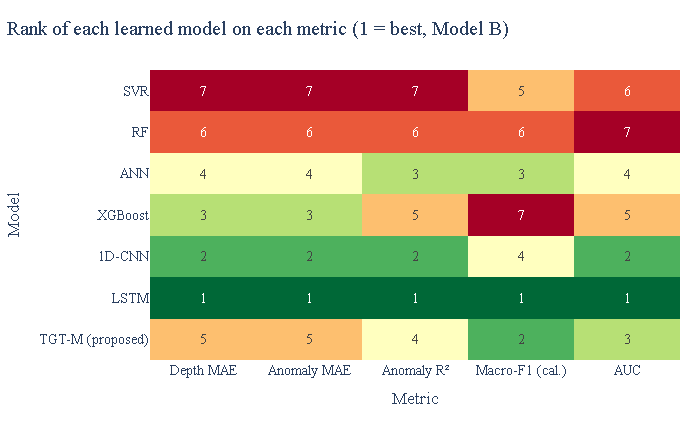

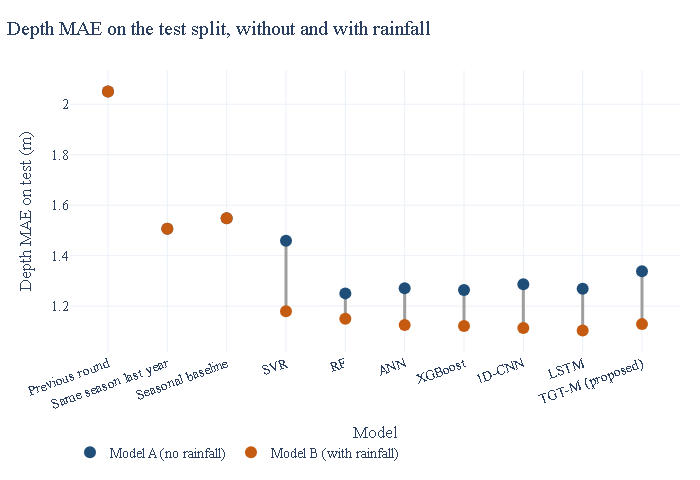

In [17]:
cs = pd.read_csv(T / "chrono_summary.csv"); cc = pd.read_csv(T / "chrono_calibrated.csv")
B_ = cs[cs.variant == "B"].set_index("model").join(cc[cc.variant == "B"].set_index("model")[["cal_macro_F1_mean"]])
tab = B_.loc[[k for k in order if k in B_.index], ["depth_MAE_mean", "anom_MAE_mean", "anom_R2_mean", "cal_macro_F1_mean", "AUC_stressed_mean"]].copy()
tab.index = [lab(k) for k in tab.index]
display(tab.rename(columns={"depth_MAE_mean": "Depth MAE (m)", "anom_MAE_mean": "Anomaly MAE", "anom_R2_mean": "Anomaly R²", "cal_macro_F1_mean": "Macro-F1 (cal.)", "AUC_stressed_mean": "AUC"}).round(3))
learned = [k for k in order if k not in order[:3]]
rank = B_.loc[learned, "depth_MAE_mean"].sort_values()
print("Ranking by depth MAE (lower is better):", " < ".join(f"{lab(k)} {v:.3f}" for k, v in rank.items()))
check("TGT-M ranks 5th of 7 learned models on depth MAE", list(rank.index).index("TGT-M") == 4)
met = {"Depth MAE": ("depth_MAE_mean", True), "Anomaly MAE": ("anom_MAE_mean", True), "Anomaly R\u00b2": ("anom_R2_mean", False), "Macro-F1 (cal.)": ("cal_macro_F1_mean", False), "AUC": ("AUC_stressed_mean", False)}
rk = pd.DataFrame({k: B_.loc[learned, c].rank(ascending=asc) for k, (c, asc) in met.items()})
fig = go.Figure(go.Heatmap(z=rk.values, x=list(rk.columns), y=[lab(k) for k in rk.index], colorscale="RdYlGn_r", text=rk.values.astype(int), texttemplate="%{text}", showscale=False))
show(fig, "Rank of each learned model on each metric (1 = best, Model B)", "Metric", "Model", h=430, yaxis_autorange="reversed")
sa, sb = [cs[cs.variant == v].set_index("model") for v in ("A", "B")]
ks = [k for k in order if k in sa.index and k in sb.index]
fig = go.Figure(); dumbbell(fig, [lab(k) for k in ks], [sa.loc[k, "depth_MAE_mean"] for k in ks], [sb.loc[k, "depth_MAE_mean"] for k in ks], "Model A (no rainfall)", "Model B (with rainfall)", PAL["A"], PAL["B"])
show(fig, "Depth MAE on the test split, without and with rainfall", "Model", "Depth MAE on test (m)", h=480, xaxis_tickangle=-20)

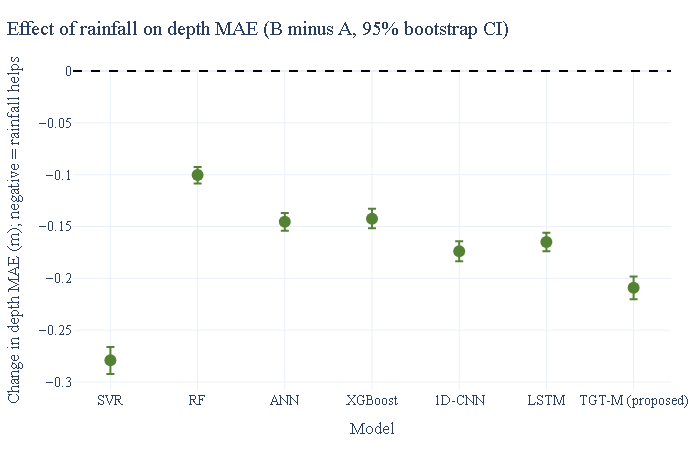

PASS  rainfall lowers the depth error of every model and no interval includes zero


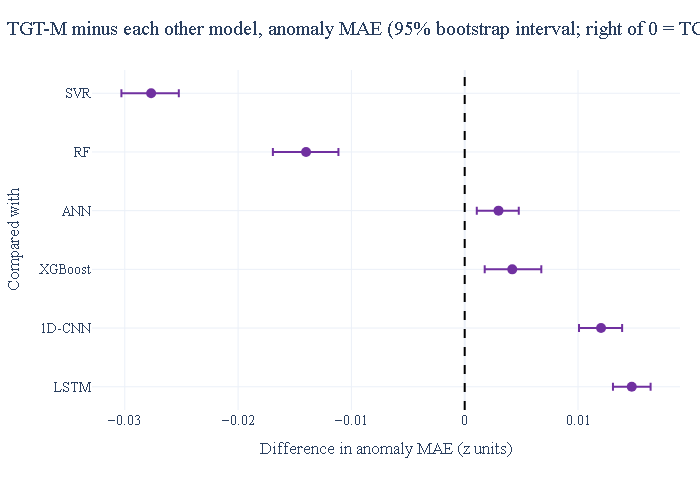

In [18]:
bt = pd.read_csv(T / "bootstrap.csv")
r_ = bt[bt.comparison.str.endswith("(rainfall effect)") & (bt.metric == "depth_MAE")].copy(); r_["model"] = r_.comparison.str.split(":").str[0].map(lab)
fig = go.Figure(go.Scatter(x=r_.model, y=r_["diff"], mode="markers", marker=dict(size=12, color=PAL["G"]), error_y=dict(type="data", symmetric=False, array=r_.ci_hi - r_["diff"], arrayminus=r_["diff"] - r_.ci_lo)))
fig.add_hline(y=0, line_dash="dash", line_color="black")
show(fig, "Effect of rainfall on depth MAE (B minus A, 95% bootstrap CI)", "Model", "Change in depth MAE (m); negative = rainfall helps", h=460)
check("rainfall lowers the depth error of every model and no interval includes zero", (r_.ci_hi < 0).all() and len(r_) == 7)
t_ = bt[bt.comparison.str.startswith("TGT-M(B) - ") & (bt.metric == "anom_MAE")].copy(); t_["other"] = t_.comparison.str.extract(r"- (.*)\(B\)")[0].map(lab)
t_ = t_[~t_.other.isin(["Previous round", "Same season last year", "Seasonal baseline"])]   # naive baselines (-0.2 to -0.7) left out for scale
fig = go.Figure(go.Scatter(x=t_["diff"], y=t_.other, mode="markers", marker=dict(size=10, color=PAL["T"]), error_x=dict(type="data", symmetric=False, array=t_.ci_hi - t_["diff"], arrayminus=t_["diff"] - t_.ci_lo)))
fig.add_vline(x=0, line_dash="dash", line_color="black")
show(fig, "TGT-M minus each other model, anomaly MAE (95% bootstrap interval; right of 0 = TGT-M worse)", "Difference in anomaly MAE (z units)", "Compared with", h=480, yaxis_autorange="reversed")

**Generalization to unseen states.** Time-respecting hold-out: train on the other states (2000-2015), test on the held-out states (2018-2022). Held-out wells keep their own earlier readings as inputs (the baseline is per well), so this tests transfer to new regions with history, not cold-start wells.

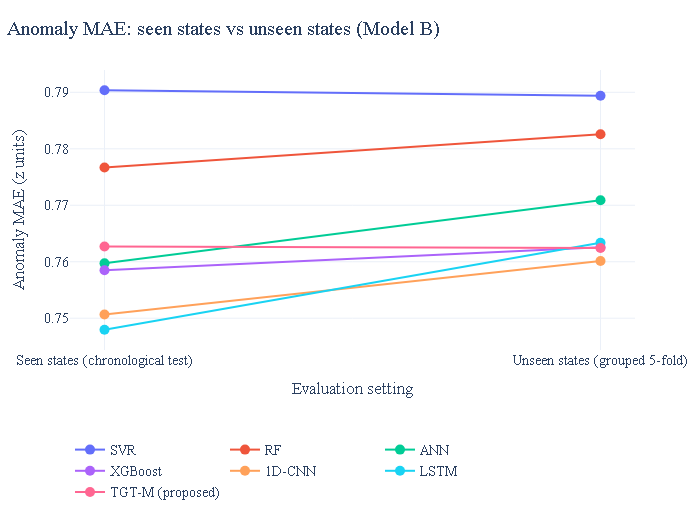

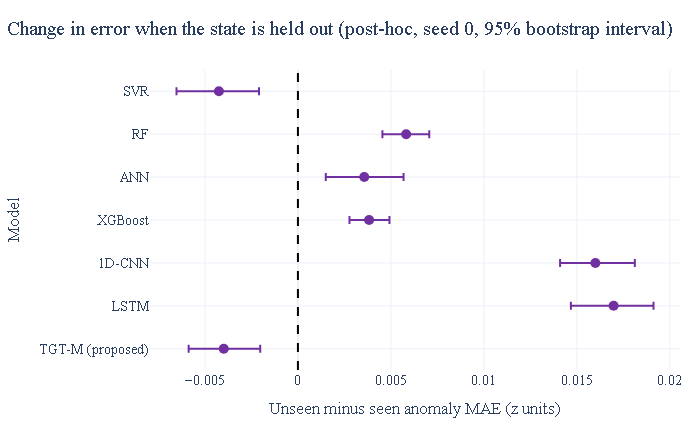

Unseen-state error is within about -0.1% to +2% of seen-state error for every model; TGT-M's change is the smallest (post-hoc robustness, not accuracy).


In [19]:
g = pd.read_csv(T / "geo_summary.csv"); g = g[(g.scheme == "g5") & (g.variant == "B")].set_index("model")
ks = [k for k in order if k in g.index]; ch_ = cs[cs.variant == "B"].set_index("model")
fig = go.Figure()
for k in ks:
    fig.add_scatter(x=["Seen states (chronological test)", "Unseen states (grouped 5-fold)"], y=[ch_.loc[k, "anom_MAE_mean"], g.loc[k, "anom_MAE"]], mode="lines+markers", name=lab(k), marker=dict(size=10))
show(fig, "Anomaly MAE: seen states vs unseen states (Model B)", "Evaluation setting", "Anomaly MAE (z units)", h=520)
gap = pd.read_csv(T / "generalization_gap.csv"); gp = gap[gap.what == "own gap"].copy(); gp["model"] = gp.comparison.map(lab)
fig = go.Figure(go.Scatter(x=gp.estimate, y=gp.model, mode="markers", marker=dict(size=10, color=PAL["T"]), error_x=dict(type="data", symmetric=False, array=gp.ci_hi - gp.estimate, arrayminus=gp.estimate - gp.ci_lo)))
fig.add_vline(x=0, line_dash="dash", line_color="black")
show(fig, "Change in error when the state is held out (post-hoc, seed 0, 95% bootstrap interval)", "Unseen minus seen anomaly MAE (z units)", "Model", h=440, yaxis_autorange="reversed")
print("Unseen-state error is within about -0.1% to +2% of seen-state error for every model; TGT-M's change is the smallest (post-hoc robustness, not accuracy).")

## 8 · The two pre-registered tests (slide: Pre-registered Tests of TGT-M)
Because TGT-M is not the most accurate point predictor, two tests of its design claims were **written down before running** (`docs/preregistration_review2.md`).
**H1:** its 80% prediction intervals are better (lower interval score) than quantile XGBoost and than split-conformal intervals of the other models. **H2:** when recent readings are missing at test time (20, 40, 60% removed), it loses less accuracy than LSTM and 1D-CNN (H2a) and has the lowest error at 60% (H2b).

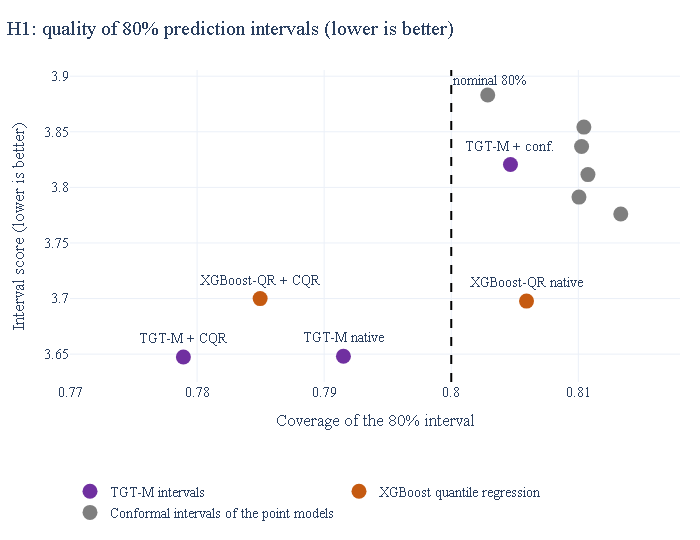

,method,coverage,width,interval_score
0,TGT-M native,0.792,2.319,3.648
1,TGT-M + CQR,0.779,2.249,3.647
2,XGBoost-QR native,0.806,2.503,3.698
3,XGBoost-QR + CQR,0.785,2.401,3.700
4,SVR point + conformal,0.803,2.474,3.883
5,RF point + conformal,0.810,2.467,3.854
6,ANN point + conformal,0.811,2.425,3.811
7,XGBoost point + conformal,0.810,2.410,3.837
8,CNN1D point + conformal,0.810,2.403,3.791
9,LSTM point + conformal,0.813,2.403,3.776


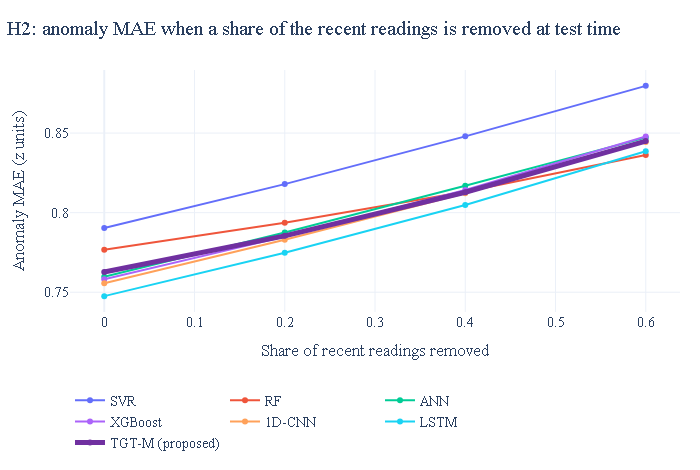

Degradation from 0% to 60% removed: {'RF': 0.0595, 'TGT-M (proposed)': 0.0823, 'ANN': 0.0874, '1D-CNN': 0.0889, 'SVR': 0.0893, 'XGBoost': 0.0897, 'LSTM': 0.0911}
Lowest error at 60% removed: RF
PASS  H1 supported: TGT-M interval score below XGBoost quantile regression
PASS  H2a supported: TGT-M degrades less than LSTM and 1D-CNN
PASS  H2b NOT supported (reported honestly): Random Forest has the lowest error at 60% removal


In [20]:
I = pd.read_csv(T / "interval_summary.csv")
I["grp"] = np.where(I.method.str.startswith("TGT-M"), "TGT-M intervals", np.where(I.method.str.startswith("XGBoost-QR"), "XGBoost quantile regression", "Conformal intervals of the point models"))
fig = go.Figure()
for gname, gc in (("TGT-M intervals", PAL["T"]), ("XGBoost quantile regression", PAL["B"]), ("Conformal intervals of the point models", PAL["grey"])):
    d_ = I[I.grp == gname]; show_t = gname != "Conformal intervals of the point models"
    fig.add_scatter(x=d_.coverage, y=d_.interval_score, mode="markers+text" if show_t else "markers", name=gname, marker=dict(size=15, color=gc),
                    text=list(d_.method.str.replace(" point + conformal", " + conf.")) if show_t else None, textposition="top center", hovertext=list(d_.method))
fig.add_vline(x=0.8, line_dash="dash", line_color="black", annotation_text="nominal 80%")
show(fig, "H1: quality of 80% prediction intervals (lower is better)", "Coverage of the 80% interval", "Interval score (lower is better)", h=540, xaxis_range=[0.770, 0.818])
display(I[["method", "coverage", "width", "interval_score"]].round(3))
R_ = pd.read_csv(T / "robust_summary.csv"); fig = go.Figure()
for k in ["SVR", "RF", "ANN", "XGBoost", "CNN1D", "LSTM", "TGT-M"]:
    d_ = R_[R_.model == k]; fig.add_scatter(x=d_.p, y=d_["mean"], mode="lines+markers", name=lab(k), line=dict(width=5 if k == "TGT-M" else 2, color=PAL["T"] if k == "TGT-M" else None))
show(fig, "H2: anomaly MAE when a share of the recent readings is removed at test time", "Share of recent readings removed", "Anomaly MAE (z units)", h=470)
deg = (R_[R_.p == 0.6].set_index("model")["mean"] - R_[R_.p == 0.0].set_index("model")["mean"]).sort_values()
print("Degradation from 0% to 60% removed:", {lab(k): round(v, 4) for k, v in deg.items()})
print("Lowest error at 60% removed:", lab(R_[R_.p == 0.6].set_index("model")["mean"].idxmin()))
check("H1 supported: TGT-M interval score below XGBoost quantile regression", float(I.set_index("method").loc["TGT-M native", "interval_score"]) < float(I.set_index("method").loc["XGBoost-QR native", "interval_score"]))
check("H2a supported: TGT-M degrades less than LSTM and 1D-CNN", deg["TGT-M"] < deg["LSTM"] and deg["TGT-M"] < deg["CNN1D"])
check("H2b NOT supported (reported honestly): Random Forest has the lowest error at 60% removal", R_[R_.p == 0.6].set_index("model")["mean"].idxmin() == "RF")

## 9 · Key findings and self-check (slide: Key Findings and Limitations)
* Every learned model beats the seasonal baseline; **rainfall lowers the depth error of every model** (8-19%, all intervals exclude zero).
* **TGT-M ranks 5th of 7** on depth MAE; LSTM, 1D-CNN, XGBoost and ANN are slightly better, TGT-M is better than RF and SVR.
* **Supported strengths:** better 80% intervals than quantile XGBoost and than conformal intervals of all six models (H1); smaller loss than LSTM / 1D-CNN with missing recent readings (H2a). **Not supported:** lowest error at 60% missing (H2b, RF is lowest).
* Unseen states: error stays within about 2% of seen-state error; TGT-M's change is the smallest (post-hoc).
* Limits: anomaly R² about 0.2-0.3 so four-class macro-F1 stays low for all models; sparse May series; small hyperparameter search; Spark run in local mode; cold-start wells not tested.

In [21]:
ok = sum(v for _, v in CHECKS)
print(f"{ok} of {len(CHECKS)} checks passed")
if ok == len(CHECKS):
    print("ALL CHECKS PASSED")
else:
    print("CHECK FAILED:", [n for n, v in CHECKS if not v])

17 of 17 checks passed
ALL CHECKS PASSED


### Where things are
`modeling/` code (nets.py = TGT-M, data.py = inputs, lib.py = training, spark_check.py = Spark) | `results/tables/` all result tables | `results/powerbi/` CSVs for Power BI / Tableau | `docs/preregistration_review2.md` | `notebooks/2_Full_Pipeline.ipynb` retrains everything (hours).